# LEGO · Autoencoder de color: VAE y DiTo

**Esta libreta entrena solo con LEGO.** Aprende a comprimir el color de una estampa y
reconstruirlo condicionado por su alfa. Las fotos humanas y el Flow 2 se entrenan en otra libreta.

Ejecuta todas las celdas en orden. Compara un VAE de control y un DiTo de color pequeño;
selecciona con validación y reserva test para la evaluación final. Guarda **best y last**, EMA,
curvas, 100 ejemplos de test como máximo y un paquete completo para el futuro Flow 2.

**Inputs de Kaggle:** `LegosPartsVae`, las intermedias con `dataset.csv` y `dataset/*.png`,
y la salida de geometría DiTo con `manifest.csv` (puede venir dentro de su ZIP).
Si agregas la salida del Flow 1, reutiliza automáticamente `pares_auditados.csv` y sus splits.
No requiere descargar modelos ni reinstalar PyTorch, Transformers o Hugging Face.

La geometría se conserva con centrado y padding, **sin redimensionar**. Colores distintos con el
mismo alfa permanecen como ejemplos distintos. Los resúmenes se actualizan cada **100 pasos**;
los procesos medianos y largos muestran `tqdm`.

DiTo reutiliza encoder, bloques y sampler de la implementación que funcionó en geometría,
adaptados a RGB y condición de máscara. Es una adaptación al proyecto, no un resultado del paper.

In [1]:
import os, sys, json, math, time, copy, random, hashlib, zipfile, importlib.util, gc
from pathlib import Path
from contextlib import nullcontext
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

if importlib.util.find_spec('einops') is None:
    raise ImportError('Falta einops. Ejecuta una vez: %pip install einops --no-deps')

CONFIG = dict(
    VERSION='color_v2', RAIZ='/kaggle/input', SALIDA='/kaggle/working/lego_color',
    PARQUET=None, CSV_INTER=None, MANIFEST_DITO=None, PARES_AUDITADOS=None,
    # Si hay varios datasets con archivos diferentes del mismo nombre, fija su ruta arriba.
    EXPERIMENTOS=['vae_control', 'dito_color'],  # opcional: añadir 'dito_color_sync'
    SEMILLA=42, LADO=128, Z_CHANNELS=8, CANALES=[32,64,128],
    PASOS=6000, LOTE=4, ACUMULAR=2, LR=2e-4, WD=0.01, WARMUP=300,
    LR_FINAL=0.05, CLIP=1.0, EMA=0.999, LOG_CADA=100, EVAL_CADA=500,
    CHECKPOINT_CADA=500, BETA=1e-4, CALENTAMIENTO_KL=0.1,
    AUMENTOS=True, SYNC_P=0.1, FM_SIGMA_MIN=1e-5, TIME_SCALE=1000.,
    PASOS_ODE_VAL=32, PASOS_ODE_FINAL=32, LOTE_EVAL=4, N_VAL=32,
    N_TEST=100, POR_PAGINA=10, N_ABLACION=16, N_INTERPOLACIONES=3,
    INTER_TEST=0.1, INTER_VAL=0.1, REANUDAR=True, REANUDAR_INPUT=True,
    # Pesos compatibles de una corrida previa: se inicia un optimizador nuevo.
    PESOS_INICIALES={'vae_control':None, 'dito_color':None, 'dito_color_sync':None},
    # No usar esta opción para medir calidad: comprueba infraestructura con imágenes artificiales.
    SMOKE=os.environ.get('LEGO_COLOR_SMOKE','0')=='1',
)
if CONFIG['SMOKE']:
    CONFIG.update(PASOS=2, LOTE=1, ACUMULAR=1, WARMUP=1, EVAL_CADA=2,
                  CHECKPOINT_CADA=2, N_VAL=2, N_TEST=2, N_ABLACION=2,
                  PASOS_ODE_VAL=2, PASOS_ODE_FINAL=2, LOTE_EVAL=1,
                  N_INTERPOLACIONES=1, REANUDAR_INPUT=False, AUMENTOS=False)
    CONFIG['SALIDA']=os.environ.get('LEGO_COLOR_SMOKE_OUT','/tmp/lego_color_smoke')
assert CONFIG['LOG_CADA']==100, 'Los resúmenes de entrenamiento se muestran cada 100 pasos.'
assert CONFIG['LADO']==128 and CONFIG['Z_CHANNELS']==8
assert set(CONFIG['EXPERIMENTOS']) <= {'vae_control','dito_color','dito_color_sync'}
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP=DEVICE.type=='cuda'
if DEVICE.type=='cpu': torch.set_num_threads(min(4, os.cpu_count() or 1))
RUN=Path(CONFIG['SALIDA'])/CONFIG['VERSION']; RUN.mkdir(parents=True,exist_ok=True)
def fijar_semilla(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
def amp_ctx():
    return torch.autocast('cuda',dtype=torch.float16) if AMP else nullcontext()
def sha_file(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(1<<20),b''): h.update(b)
    return h.hexdigest()
def atomic_save(obj,path):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_suffix(path.suffix+'.tmp'); torch.save(obj,tmp); tmp.replace(path)
fijar_semilla(CONFIG['SEMILLA'])
torch.backends.cudnn.benchmark=AMP
print('Dispositivo:',DEVICE,'| AMP:',AMP,'| modelos:',CONFIG['EXPERIMENTOS'])
print('Salida:',RUN,'| lote efectivo:',CONFIG['LOTE']*CONFIG['ACUMULAR'])
if CONFIG['SMOKE']: print('SMOKE: datos artificiales; NO mide calidad LEGO.')

Dispositivo: cuda | AMP: True | modelos: ['vae_control', 'dito_color']
Salida: /kaggle/working/lego_color/color_v2 | lote efectivo: 8


## Datos, colores y particiones

Se usa el alfa original como soporte; la piel transparente se elegirá aparte en el modelo 3D.
Se comprueban hashes de máscaras contra el manifiesto DiTo. Si está disponible, el split del
Flow 1 tiene prioridad: `val_personas` sigue siendo geometría de train para este autoencoder.
Sin ese CSV, se respetan los splits originales y se reservan familias de intermedias juntas.
Sus padres pueden pertenecer a train: es evaluación de combinaciones nuevas, no de linajes inéditos.

In [2]:
def hash_mask(a):
    return hashlib.sha256(np.ascontiguousarray(a,dtype=np.float32).tobytes()).hexdigest()

def canonical_rgba(path):
    with Image.open(path) as im:
        if 'A' not in im.getbands() and 'transparency' not in im.info:
            raise ValueError(f'Estampa sin alfa: {path}')
        a=np.asarray(im.convert('RGBA')).copy()
    h,w=a.shape[:2]; side=CONFIG['LADO']
    if h>side or w>side: raise ValueError(f'{path}: {w}x{h}; se requiere el mismo marco que Flow 1, <=128.')
    m=a[:,:,3]>=128
    if not (0<m.mean()<1): raise ValueError(f'Alfa vacío/completo: {path}')
    out=np.zeros((4,side,side),dtype=np.uint8); y=(side-h)//2; x=(side-w)//2
    out[:3,y:y+h,x:x+w]=(a[:,:,:3]*m[:,:,None]).transpose(2,0,1)
    out[3,y:y+h,x:x+w]=m.astype(np.uint8)*255
    return out

def select_file(paths,label):
    paths=sorted(set(Path(p) for p in paths if Path(p).is_file()),key=lambda p:(len(str(p)),str(p)))
    if not paths: raise FileNotFoundError(label)
    if len(paths)>1 and len({sha_file(p) for p in paths})>1:
        raise ValueError(f'{label}: hay varias versiones diferentes; fija la ruta en CONFIG: {[str(p) for p in paths]}')
    return paths[0]

def cargar_registros():
    if CONFIG['SMOKE']:
        root=RUN/'fixture';root.mkdir(exist_ok=True); rows=[]; metas=[]
        for i in range(18):
            a=np.zeros((118,128,4),np.uint8)
            a[23:32,24:35,:3]=[30+i*3,40,55];a[23:32,24:35,3]=255
            a[23:32,80:91,:3]=[30+i*3,40,55];a[23:32,80:91,3]=255
            a[65:68+i%6,45:75,:3]=[160,20+i*4,35];a[65:68+i%6,45:75,3]=255
            a[80+i,12+i,:3]=[i,100,200];a[80+i,12+i,3]=255
            p=root/f's{i:02d}.png';Image.fromarray(a).save(p)
            split='entrenamiento' if i<12 else ('validacion' if i<15 else 'prueba')
            rows.append(dict(id=f'real:s{i:02d}',pieza=f's{i:02d}',tipo='real',ruta=str(p),fuente='fixture',pieza_a='',pieza_b=''))
            metas.append(dict(id=rows[-1]['id'],tipo='real',particion=split,sha_mask=hash_mask(canonical_rgba(p)[3]/255)))
        # Igual alfa, color diferente: debe sobrevivir a la deduplicación de color.
        a=np.asarray(Image.open(root/'s00.png')).copy();a[:,:,:3]=np.where(a[:,:,3,None]>0,[190,70,40],0)
        p=root/'s00_color.png';Image.fromarray(a).save(p)
        rows.append(dict(id='real:s00_color',pieza='s00_color',tipo='real',ruta=str(p),fuente='fixture',pieza_a='',pieza_b=''))
        return pd.DataFrame(rows),pd.DataFrame(metas),pd.DataFrame(),{}

    root=Path(CONFIG['RAIZ'])
    files=[p for p in tqdm(root.rglob('*'),desc='Indexando inputs',unit='ruta') if p.is_file()]
    def table(name,columns,preset=None,optional=False):
        if preset:
            p=Path(preset); assert p.is_file(),p
            return p
        cand=[]
        for p in files:
            if p.name!=name: continue
            try:
                if columns <= set(pd.read_csv(p,nrows=0).columns): cand.append(p)
            except (ValueError,pd.errors.ParserError,UnicodeDecodeError): pass
        if not cand and optional:return None
        return select_file(cand,f'No encuentro {name} con columnas {sorted(columns)}')

    parq=Path(CONFIG['PARQUET']) if CONFIG['PARQUET'] else select_file([p for p in files if p.name=='caras_vae.parquet'],'Falta caras_vae.parquet')
    ds_path=table('dataset.csv',{'id','pieza_a','pieza_b','estado'},CONFIG['CSV_INTER'])
    meta_path=table('manifest.csv',{'id','tipo','particion','sha_mask'},CONFIG['MANIFEST_DITO'],True)
    # Los outputs DiTo pueden añadirse como ZIP sin descomprimir. Solo se extrae manifest.csv.
    if meta_path is None:
        candidates=[]
        for zp in tqdm([p for p in files if p.suffix.lower()=='.zip'],desc='Buscando manifiesto DiTo',unit='zip'):
            with zipfile.ZipFile(zp) as z:
                for member in z.namelist():
                    if Path(member).name=='manifest.csv':
                        b=z.read(member)
                        import io
                        if {'id','tipo','particion','sha_mask'} <= set(pd.read_csv(io.BytesIO(b),nrows=0).columns):
                            p=RUN/'manifiestos_input'/f'{hashlib.sha256(b).hexdigest()}.csv'
                            p.parent.mkdir(exist_ok=True);p.write_bytes(b);candidates.append(p)
        meta_path=select_file(candidates,'Falta manifest.csv de geometría: añade el output DiTo o fija MANIFEST_DITO')
    audited_path=table('pares_auditados.csv',{'pieza','version','split_flow'},CONFIG['PARES_AUDITADOS'],True)
    meta=pd.read_csv(meta_path,keep_default_na=False,dtype=str)
    audited=pd.read_csv(audited_path,keep_default_na=False,dtype=str) if audited_path else pd.DataFrame()
    cat=pd.read_parquet(parq)
    assert {'pieza','ruta'} <= set(cat.columns),cat.columns
    if 'excluir' in cat:
        ex=cat.excluir.astype(str).str.lower().isin(['true','1','1.0','si','sí'])
        cat=cat[~ex]
    cat=cat.copy();cat['pieza']=cat.pieza.astype(str)
    if cat.pieza.duplicated().any():raise ValueError('pieza duplicada en caras_vae.parquet: revisar catálogo')
    pngs={}
    for p in files:
        if p.suffix.lower()=='.png':pngs.setdefault(p.stem,[]).append(p)
    def real_path(row):
        rel=Path(str(row['ruta']))
        direct=[rel,parq.parent/rel,parq.parent/'caras_torsos'/rel]
        hits=[p for p in direct if p.is_file()]
        if not hits:
            suffix=Path(*rel.parts[-3:])
            hits=[p for p in pngs.get(str(row['pieza']),[]) if str(p).endswith(str(suffix))]
        if not hits:
            hits=[p for p in pngs.get(str(row['pieza']),[]) if 'caras_frente' in p.parts]
        return select_file(hits,f'No puedo resolver estampa original {row["pieza"]}, ruta={rel}')
    rows=[]
    for row in tqdm(cat.to_dict('records'),desc='Resolviendo LEGO originales',unit='cara'):
        rows.append(dict(id='real:'+row['pieza'],pieza=row['pieza'],tipo='real',ruta=str(real_path(row)),
                         fuente=str(row.get('fuente','original')),pieza_a='',pieza_b=''))
    ds=pd.read_csv(ds_path,keep_default_na=False,dtype=str)
    if ds.id.duplicated().any(): raise ValueError('IDs de intermedias duplicados')
    ds=ds[ds.estado.isin(['pasa','dudosa'])]
    known_pieces={r['pieza'] for r in rows}
    for row in tqdm(ds.to_dict('records'),desc='Resolviendo LEGO intermedios',unit='cara'):
        if not {row['pieza_a'],row['pieza_b']} <= known_pieces:
            raise ValueError(f'Padre fuera del catálogo: {row["id"]}')
        p=ds_path.parent/'dataset'/f'{row["id"]}.png'
        if not p.is_file():raise FileNotFoundError(p)
        rows.append(dict(id='int:'+row['id'],pieza=row['id'],tipo='intermedia',ruta=str(p),
                         fuente='intermedia',pieza_a=row['pieza_a'],pieza_b=row['pieza_b']))
    hashes={str(p):sha_file(p) for p in [parq,ds_path,meta_path]+([audited_path] if audited_path else [])}
    print('Partición Flow 1:',str(audited_path) if audited_path else 'no adjunta; se reserva por familias')
    return pd.DataFrame(rows),meta,audited,hashes

registros,meta,audited,SOURCE_SHA=cargar_registros()
assert registros.id.is_unique
arrays=[]
for row in tqdm(registros.itertuples(),total=len(registros),desc='Cargando y verificando RGBA',unit='estampa'):
    c=canonical_rgba(row.ruta);arrays.append(c)
    sm=hash_mask(c[3]/255); expected=meta[meta.id.eq(row.id)]
    if len(expected) and set(expected.sha_mask)!={sm}:raise ValueError(f'Alfa distinto al manifiesto DiTo: {row.id}')
    if sm not in set(meta.sha_mask):raise ValueError(f'Alfa desconocido en manifiesto DiTo: {row.id}')
    registros.loc[registros.id.eq(row.id),'sha_mask']=sm
    registros.loc[registros.id.eq(row.id),'sha_color']=hashlib.sha256(c.tobytes()).hexdigest()

# Resolver etiquetas del Flow 1 por pieza, o del manifiesto de originales por alfa.
fixed={}
if len(audited):
    audited['id_color']=np.where(audited.version.eq('gi'),'int:','real:')+audited.pieza
    audited['split_color']=audited.split_flow.replace({'val_personas':'entrenamiento'})
    for cid,g in audited.groupby('id_color'):
        labels=set(g.split_color)
        if len(labels)!=1:raise ValueError(f'Particiones incompatibles para {cid}: {labels}')
        fixed[cid]=next(iter(labels))
for row in registros[registros.tipo.eq('real')].itertuples():
    if row.id not in fixed:
        labels=set(meta.loc[meta.sha_mask.eq(row.sha_mask),'particion'])
        if len(labels)!=1:raise ValueError(f'Split original ambiguo: {row.id}: {labels}')
        fixed[row.id]=next(iter(labels))
assert set(fixed.values()) <= {'entrenamiento','validacion','prueba'}

# Componentes: misma geometría y misma pareja de padres permanecen juntas.
parent={}
def find(x):
    parent.setdefault(x,x)
    if parent[x]!=x: parent[x]=find(parent[x])
    return parent[x]
def union(a,b):parent[find(a)]=find(b)
for row in registros.itertuples():
    union(row.id,'mask:'+row.sha_mask)
    if row.tipo=='intermedia':union(row.id,'family:'+'|'.join(sorted([row.pieza_a,row.pieza_b])))
for row in registros[registros.tipo.eq('intermedia')].itertuples():
    for p in [row.pieza_a,row.pieza_b]:
        if fixed.get('real:'+p)!='entrenamiento':raise ValueError(f'Intermedia {row.id}: padre {p} fuera de train')
registros['componente']=[find(i) for i in registros.id]
for comp,g in registros.groupby('componente'):
    labels={fixed[i] for i in g.id if i in fixed}
    if len(labels)>1:raise ValueError(f'La familia/geometría cruza splits autoritativos: {g.id.tolist()[:10]} {labels}')
    key='|'.join(sorted(g.sha_mask.unique()))
    f=int(hashlib.sha256((str(CONFIG['SEMILLA'])+'|'+key).encode()).hexdigest()[:12],16)/16**12
    split=next(iter(labels)) if labels else ('prueba' if f<CONFIG['INTER_TEST'] else
          'validacion' if f<CONFIG['INTER_TEST']+CONFIG['INTER_VAL'] else 'entrenamiento')
    registros.loc[g.index,'particion']=split

# Solo se deduplica RGBA visible idéntico; nunca exclusivamente el alfa.
registros['color_i']=pd.factorize(registros.sha_color,sort=False)[0]
keep=registros.drop_duplicates('color_i').index.to_numpy()
tabla=registros.loc[keep].copy().reset_index(drop=True)
CARAS=torch.from_numpy(np.stack([arrays[i] for i in keep]))
del arrays
assert np.array_equal(tabla.color_i.to_numpy(),np.arange(len(tabla)))
assert not registros.groupby('sha_color').particion.nunique().gt(1).any()
assert not registros.groupby('sha_mask').particion.nunique().gt(1).any()
IDX={p:np.flatnonzero(tabla.particion.eq(p)) for p in ['entrenamiento','validacion','prueba']}
if min(map(len,IDX.values()))==0:raise ValueError('Train/val/test vacíos; revisar particiones, no se mezclan automáticamente.')
MANIFEST_SHA=hashlib.sha256(registros[['id','sha_color','particion']].to_csv(index=False).encode()).hexdigest()
registros.to_csv(RUN/'manifest_color_aliases.csv',index=False)
tabla.to_csv(RUN/'manifest_color.csv',index=False)
json.dump(SOURCE_SHA,open(RUN/'fuentes_sha256.json','w'),indent=2)
display(tabla.groupby(['tipo','particion']).size().rename('estampas_color').to_frame())
print('RGBA únicos:',len(tabla),'| máscaras únicas:',tabla.sha_mask.nunique(),'| alias:',len(registros))
print('Memoria de imágenes uint8 en CPU:',round(CARAS.nelement()/2**20,1),'MiB')

def batch(indices):
    return CARAS[torch.as_tensor(indices,dtype=torch.long)].to(DEVICE).float()/255.

Indexando inputs: 0ruta [00:00, ?ruta/s]

Resolviendo LEGO originales:   0%|          | 0/505 [00:00<?, ?cara/s]

Resolviendo LEGO intermedios:   0%|          | 0/2150 [00:00<?, ?cara/s]

Partición Flow 1: no adjunta; se reserva por familias


Cargando y verificando RGBA:   0%|          | 0/2655 [00:00<?, ?estampa/s]

estampas_color
tipo       particion                    
intermedia entrenamiento            1714
           prueba                    230
           validacion                206
real       entrenamiento             395
           prueba                     52
           validacion                 48

RGBA únicos: 2645 | máscaras únicas: 2637 | alias: 2655
Memoria de imágenes uint8 en CPU: 165.3 MiB


## Implementación DiTo incluida

Se incluyen las fuentes y su licencia, sin depender de Internet. Encoder y U-Net provienen del
DiTo usado en geometría (commit `d2dc2993ffc627ebf2240d54a2afe153a59554a7`);
la salida se adapta a tres canales. La máscara se inyecta también en las escalas internas.
No carga los pesos binarios de Flow 1 como si fueran un modelo de color.

In [3]:
UPSTREAM_TEXT = {'codec.py': '# pytorch_diffusion + derived encoder decoder\nimport math\nimport torch\nimport torch.nn as nn\nimport numpy as np\nfrom einops import rearrange\n\nfrom upstream_registry import register\n\n\nclass LinearAttention(nn.Module):\n    def __init__(self, dim, heads=4, dim_head=32):\n        super().__init__()\n        self.heads = heads\n        hidden_dim = dim_head * heads\n        self.to_qkv = nn.Conv2d(dim, hidden_dim * 3, 1, bias = False)\n        self.to_out = nn.Conv2d(hidden_dim, dim, 1)\n\n    def forward(self, x):\n        b, c, h, w = x.shape\n        qkv = self.to_qkv(x)\n        q, k, v = rearrange(qkv, \'b (qkv heads c) h w -> qkv b heads c (h w)\', heads = self.heads, qkv=3)\n        k = k.softmax(dim=-1)\n        context = torch.einsum(\'bhdn,bhen->bhde\', k, v)\n        out = torch.einsum(\'bhde,bhdn->bhen\', context, q)\n        out = rearrange(out, \'b heads c (h w) -> b (heads c) h w\', heads=self.heads, h=h, w=w)\n        return self.to_out(out)\n\n\ndef get_timestep_embedding(timesteps, embedding_dim):\n    """\n    This matches the implementation in Denoising Diffusion Probabilistic Models:\n    From Fairseq.\n    Build sinusoidal embeddings.\n    This matches the implementation in tensor2tensor, but differs slightly\n    from the description in Section 3.5 of "Attention Is All You Need".\n    """\n    assert len(timesteps.shape) == 1\n\n    half_dim = embedding_dim // 2\n    emb = math.log(10000) / (half_dim - 1)\n    emb = torch.exp(torch.arange(half_dim, dtype=torch.float32) * -emb)\n    emb = emb.to(device=timesteps.device)\n    emb = timesteps.float()[:, None] * emb[None, :]\n    emb = torch.cat([torch.sin(emb), torch.cos(emb)], dim=1)\n    if embedding_dim % 2 == 1:  # zero pad\n        emb = torch.nn.functional.pad(emb, (0,1,0,0))\n    return emb\n\n\ndef nonlinearity(x):\n    # swish\n    return x*torch.sigmoid(x)\n\n\ndef Normalize(in_channels, num_groups=32):\n    return torch.nn.GroupNorm(num_groups=num_groups, num_channels=in_channels, eps=1e-6, affine=True)\n\n\nclass Upsample(nn.Module):\n    def __init__(self, in_channels, with_conv):\n        super().__init__()\n        self.with_conv = with_conv\n        if self.with_conv:\n            self.conv = torch.nn.Conv2d(in_channels,\n                                        in_channels,\n                                        kernel_size=3,\n                                        stride=1,\n                                        padding=1)\n\n    def forward(self, x):\n        x = torch.nn.functional.interpolate(x, scale_factor=2.0, mode="nearest")\n        if self.with_conv:\n            x = self.conv(x)\n        return x\n\n\nclass Downsample(nn.Module):\n    def __init__(self, in_channels, with_conv):\n        super().__init__()\n        self.with_conv = with_conv\n        if self.with_conv:\n            # no asymmetric padding in torch conv, must do it ourselves\n            self.conv = torch.nn.Conv2d(in_channels,\n                                        in_channels,\n                                        kernel_size=3,\n                                        stride=2,\n                                        padding=0)\n\n    def forward(self, x):\n        if self.with_conv:\n            pad = (0,1,0,1)\n            x = torch.nn.functional.pad(x, pad, mode="constant", value=0)\n            x = self.conv(x)\n        else:\n            x = torch.nn.functional.avg_pool2d(x, kernel_size=2, stride=2)\n        return x\n\n\nclass ResnetBlock(nn.Module):\n    def __init__(self, *, in_channels, out_channels=None, kernel_size=3, conv_shortcut=False,\n                 dropout, temb_channels=512, normalize=True):\n        super().__init__()\n        self.in_channels = in_channels\n        out_channels = in_channels if out_channels is None else out_channels\n        self.out_channels = out_channels\n        self.use_conv_shortcut = conv_shortcut\n\n        self.norm1 = Normalize(in_channels) if normalize else torch.nn.Identity()\n        self.conv1 = torch.nn.Conv2d(in_channels,\n                                     out_channels,\n                                     kernel_size=kernel_size,\n                                     stride=1,\n                                     padding=(kernel_size - 1) // 2)\n        if temb_channels > 0:\n            self.temb_proj = torch.nn.Linear(temb_channels,\n                                             out_channels)\n        self.norm2 = Normalize(out_channels) if normalize else torch.nn.Identity()\n        self.dropout = torch.nn.Dropout(dropout)\n        self.conv2 = torch.nn.Conv2d(out_channels,\n                                     out_channels,\n                                     kernel_size=kernel_size,\n                                     stride=1,\n                                     padding=(kernel_size - 1) // 2)\n        if self.in_channels != self.out_channels:\n            if self.use_conv_shortcut:\n                self.conv_shortcut = torch.nn.Conv2d(in_channels,\n                                                     out_channels,\n                                                     kernel_size=kernel_size,\n                                                     stride=1,\n                                                     padding=(kernel_size - 1) // 2)\n            else:\n                self.nin_shortcut = torch.nn.Conv2d(in_channels,\n                                                    out_channels,\n                                                    kernel_size=1,\n                                                    stride=1,\n                                                    padding=0)\n\n    def forward(self, x, temb):\n        h = x\n        h = self.norm1(h)\n        h = nonlinearity(h)\n        h = self.conv1(h)\n\n        if temb is not None:\n            h = h + self.temb_proj(nonlinearity(temb))[:,:,None,None]\n\n        h = self.norm2(h)\n        h = nonlinearity(h)\n        h = self.dropout(h)\n        h = self.conv2(h)\n\n        if self.in_channels != self.out_channels:\n            if self.use_conv_shortcut:\n                x = self.conv_shortcut(x)\n            else:\n                x = self.nin_shortcut(x)\n\n        return x+h\n\n\nclass LinAttnBlock(LinearAttention):\n    """to match AttnBlock usage"""\n    def __init__(self, in_channels):\n        super().__init__(dim=in_channels, heads=1, dim_head=in_channels)\n\n\nclass AttnBlock(nn.Module):\n    def __init__(self, in_channels):\n        super().__init__()\n        self.in_channels = in_channels\n\n        self.norm = Normalize(in_channels)\n        self.q = torch.nn.Conv2d(in_channels,\n                                 in_channels,\n                                 kernel_size=1,\n                                 stride=1,\n                                 padding=0)\n        self.k = torch.nn.Conv2d(in_channels,\n                                 in_channels,\n                                 kernel_size=1,\n                                 stride=1,\n                                 padding=0)\n        self.v = torch.nn.Conv2d(in_channels,\n                                 in_channels,\n                                 kernel_size=1,\n                                 stride=1,\n                                 padding=0)\n        self.proj_out = torch.nn.Conv2d(in_channels,\n                                        in_channels,\n                                        kernel_size=1,\n                                        stride=1,\n                                        padding=0)\n\n\n    def forward(self, x):\n        h_ = x\n        h_ = self.norm(h_)\n        q = self.q(h_)\n        k = self.k(h_)\n        v = self.v(h_)\n\n        # compute attention\n        b,c,h,w = q.shape\n        q = q.reshape(b,c,h*w)\n        q = q.permute(0,2,1)   # b,hw,c\n        k = k.reshape(b,c,h*w) # b,c,hw\n        w_ = torch.bmm(q,k)     # b,hw,hw    w[b,i,j]=sum_c q[b,i,c]k[b,c,j]\n        w_ = w_ * (int(c)**(-0.5))\n        w_ = torch.nn.functional.softmax(w_, dim=2)\n\n        # attend to values\n        v = v.reshape(b,c,h*w)\n        w_ = w_.permute(0,2,1)   # b,hw,hw (first hw of k, second of q)\n        h_ = torch.bmm(v,w_)     # b, c,hw (hw of q) h_[b,c,j] = sum_i v[b,c,i] w_[b,i,j]\n        h_ = h_.reshape(b,c,h,w)\n\n        h_ = self.proj_out(h_)\n\n        return x+h_\n\n\ndef make_attn(in_channels, attn_type="vanilla"):\n    assert attn_type in ["vanilla", "linear", "none"], f\'attn_type {attn_type} unknown\'\n    # print(f"making attention of type \'{attn_type}\' with {in_channels} in_channels")\n    if attn_type == "vanilla":\n        return AttnBlock(in_channels)\n    elif attn_type == "none":\n        return nn.Identity(in_channels)\n    else:\n        return LinAttnBlock(in_channels)\n\n\nclass Model(nn.Module):\n    def __init__(self, *, ch, out_ch, ch_mult=(1,2,4,8), num_res_blocks,\n                 attn_resolutions, dropout=0.0, resamp_with_conv=True, in_channels,\n                 resolution, use_timestep=True, use_linear_attn=False, attn_type="vanilla"):\n        super().__init__()\n        if use_linear_attn: attn_type = "linear"\n        self.ch = ch\n        self.temb_ch = self.ch*4\n        self.num_resolutions = len(ch_mult)\n        self.num_res_blocks = num_res_blocks\n        self.resolution = resolution\n        self.in_channels = in_channels\n\n        self.use_timestep = use_timestep\n        if self.use_timestep:\n            # timestep embedding\n            self.temb = nn.Module()\n            self.temb.dense = nn.ModuleList([\n                torch.nn.Linear(self.ch,\n                                self.temb_ch),\n                torch.nn.Linear(self.temb_ch,\n                                self.temb_ch),\n            ])\n\n        # downsampling\n        self.conv_in = torch.nn.Conv2d(in_channels,\n                                       self.ch,\n                                       kernel_size=3,\n                                       stride=1,\n                                       padding=1)\n\n        curr_res = resolution\n        in_ch_mult = (1,)+tuple(ch_mult)\n        self.down = nn.ModuleList()\n        for i_level in range(self.num_resolutions):\n            block = nn.ModuleList()\n            attn = nn.ModuleList()\n            block_in = ch*in_ch_mult[i_level]\n            block_out = ch*ch_mult[i_level]\n            for i_block in range(self.num_res_blocks):\n                block.append(ResnetBlock(in_channels=block_in,\n                                         out_channels=block_out,\n                                         temb_channels=self.temb_ch,\n                                         dropout=dropout))\n                block_in = block_out\n                if curr_res in attn_resolutions:\n                    attn.append(make_attn(block_in, attn_type=attn_type))\n            down = nn.Module()\n            down.block = block\n            down.attn = attn\n            if i_level != self.num_resolutions-1:\n                down.downsample = Downsample(block_in, resamp_with_conv)\n                curr_res = curr_res // 2\n            self.down.append(down)\n\n        # middle\n        self.mid = nn.Module()\n        self.mid.block_1 = ResnetBlock(in_channels=block_in,\n                                       out_channels=block_in,\n                                       temb_channels=self.temb_ch,\n                                       dropout=dropout)\n        self.mid.attn_1 = make_attn(block_in, attn_type=attn_type)\n        self.mid.block_2 = ResnetBlock(in_channels=block_in,\n                                       out_channels=block_in,\n                                       temb_channels=self.temb_ch,\n                                       dropout=dropout)\n\n        # upsampling\n        self.up = nn.ModuleList()\n        for i_level in reversed(range(self.num_resolutions)):\n            block = nn.ModuleList()\n            attn = nn.ModuleList()\n            block_out = ch*ch_mult[i_level]\n            skip_in = ch*ch_mult[i_level]\n            for i_block in range(self.num_res_blocks+1):\n                if i_block == self.num_res_blocks:\n                    skip_in = ch*in_ch_mult[i_level]\n                block.append(ResnetBlock(in_channels=block_in+skip_in,\n                                         out_channels=block_out,\n                                         temb_channels=self.temb_ch,\n                                         dropout=dropout))\n                block_in = block_out\n                if curr_res in attn_resolutions:\n                    attn.append(make_attn(block_in, attn_type=attn_type))\n            up = nn.Module()\n            up.block = block\n            up.attn = attn\n            if i_level != 0:\n                up.upsample = Upsample(block_in, resamp_with_conv)\n                curr_res = curr_res * 2\n            self.up.insert(0, up) # prepend to get consistent order\n\n        # end\n        self.norm_out = Normalize(block_in)\n        self.conv_out = torch.nn.Conv2d(block_in,\n                                        out_ch,\n                                        kernel_size=3,\n                                        stride=1,\n                                        padding=1)\n\n    def forward(self, x, t=None, context=None):\n        #assert x.shape[2] == x.shape[3] == self.resolution\n        if context is not None:\n            # assume aligned context, cat along channel axis\n            x = torch.cat((x, context), dim=1)\n        if self.use_timestep:\n            # timestep embedding\n            assert t is not None\n            temb = get_timestep_embedding(t, self.ch)\n            temb = self.temb.dense[0](temb)\n            temb = nonlinearity(temb)\n            temb = self.temb.dense[1](temb)\n        else:\n            temb = None\n\n        # downsampling\n        hs = [self.conv_in(x)]\n        for i_level in range(self.num_resolutions):\n            for i_block in range(self.num_res_blocks):\n                h = self.down[i_level].block[i_block](hs[-1], temb)\n                if len(self.down[i_level].attn) > 0:\n                    h = self.down[i_level].attn[i_block](h)\n                hs.append(h)\n            if i_level != self.num_resolutions-1:\n                hs.append(self.down[i_level].downsample(hs[-1]))\n\n        # middle\n        h = hs[-1]\n        h = self.mid.block_1(h, temb)\n        h = self.mid.attn_1(h)\n        h = self.mid.block_2(h, temb)\n\n        # upsampling\n        for i_level in reversed(range(self.num_resolutions)):\n            for i_block in range(self.num_res_blocks+1):\n                h = self.up[i_level].block[i_block](\n                    torch.cat([h, hs.pop()], dim=1), temb)\n                if len(self.up[i_level].attn) > 0:\n                    h = self.up[i_level].attn[i_block](h)\n            if i_level != 0:\n                h = self.up[i_level].upsample(h)\n\n        # end\n        h = self.norm_out(h)\n        h = nonlinearity(h)\n        h = self.conv_out(h)\n        return h\n\n    def get_last_layer(self):\n        return self.conv_out.weight\n\n\nclass Encoder(nn.Module):\n    def __init__(self, *, ch, out_ch, ch_mult=(1,2,4,8), num_res_blocks,\n                 attn_resolutions, dropout=0.0, resamp_with_conv=True, in_channels,\n                 resolution, z_channels, double_z=True, use_linear_attn=False, attn_type="vanilla",\n                 **ignore_kwargs):\n        super().__init__()\n        if use_linear_attn: attn_type = "linear"\n        self.ch = ch\n        self.temb_ch = 0\n        self.num_resolutions = len(ch_mult)\n        self.num_res_blocks = num_res_blocks\n        self.resolution = resolution\n        self.in_channels = in_channels\n\n        # downsampling\n        self.conv_in = torch.nn.Conv2d(in_channels,\n                                       self.ch,\n                                       kernel_size=3,\n                                       stride=1,\n                                       padding=1)\n\n        curr_res = resolution\n        in_ch_mult = (1,)+tuple(ch_mult)\n        self.in_ch_mult = in_ch_mult\n        self.down = nn.ModuleList()\n        for i_level in range(self.num_resolutions):\n            block = nn.ModuleList()\n            attn = nn.ModuleList()\n            block_in = ch*in_ch_mult[i_level]\n            block_out = ch*ch_mult[i_level]\n            for i_block in range(self.num_res_blocks):\n                block.append(ResnetBlock(in_channels=block_in,\n                                         out_channels=block_out,\n                                         temb_channels=self.temb_ch,\n                                         dropout=dropout))\n                block_in = block_out\n                if curr_res in attn_resolutions:\n                    attn.append(make_attn(block_in, attn_type=attn_type))\n            down = nn.Module()\n            down.block = block\n            down.attn = attn\n            if i_level != self.num_resolutions-1:\n                down.downsample = Downsample(block_in, resamp_with_conv)\n                curr_res = curr_res // 2\n            self.down.append(down)\n\n        # middle\n        self.mid = nn.Module()\n        self.mid.block_1 = ResnetBlock(in_channels=block_in,\n                                       out_channels=block_in,\n                                       temb_channels=self.temb_ch,\n                                       dropout=dropout)\n        self.mid.attn_1 = make_attn(block_in, attn_type=attn_type)\n        self.mid.block_2 = ResnetBlock(in_channels=block_in,\n                                       out_channels=block_in,\n                                       temb_channels=self.temb_ch,\n                                       dropout=dropout)\n\n        # end\n        self.norm_out = Normalize(block_in)\n        self.conv_out = torch.nn.Conv2d(block_in,\n                                        2*z_channels if double_z else z_channels,\n                                        kernel_size=3,\n                                        stride=1,\n                                        padding=1)\n\n    def forward(self, x):\n        # timestep embedding\n        temb = None\n\n        # downsampling\n        hs = [self.conv_in(x)]\n        for i_level in range(self.num_resolutions):\n            for i_block in range(self.num_res_blocks):\n                h = self.down[i_level].block[i_block](hs[-1], temb)\n                if len(self.down[i_level].attn) > 0:\n                    h = self.down[i_level].attn[i_block](h)\n                hs.append(h)\n            if i_level != self.num_resolutions-1:\n                hs.append(self.down[i_level].downsample(hs[-1]))\n\n        # middle\n        h = hs[-1]\n        h = self.mid.block_1(h, temb)\n        h = self.mid.attn_1(h)\n        h = self.mid.block_2(h, temb)\n\n        # end\n        h = self.norm_out(h)\n        h = nonlinearity(h)\n        h = self.conv_out(h)\n        return h\n\n\nclass Decoder(nn.Module):\n    def __init__(self, *, ch, out_ch, ch_mult=(1,2,4,8), num_res_blocks,\n                 attn_resolutions, dropout=0.0, resamp_with_conv=True, in_channels,\n                 resolution, z_channels, give_pre_end=False, tanh_out=False, use_linear_attn=False,\n                 attn_type="vanilla", **ignorekwargs):\n        super().__init__()\n        if use_linear_attn: attn_type = "linear"\n        self.ch = ch\n        self.temb_ch = 0\n        self.num_resolutions = len(ch_mult)\n        self.num_res_blocks = num_res_blocks\n        self.resolution = resolution\n        self.in_channels = in_channels\n        self.give_pre_end = give_pre_end\n        self.tanh_out = tanh_out\n\n        # compute in_ch_mult, block_in and curr_res at lowest res\n        in_ch_mult = (1,)+tuple(ch_mult)\n        block_in = ch*ch_mult[self.num_resolutions-1]\n        curr_res = resolution // 2**(self.num_resolutions-1)\n        self.z_shape = (1,z_channels,curr_res,curr_res)\n        # print("Working with z of shape {} = {} dimensions.".format(\n        #     self.z_shape, np.prod(self.z_shape)))\n\n        # z to block_in\n        self.conv_in = torch.nn.Conv2d(z_channels,\n                                       block_in,\n                                       kernel_size=3,\n                                       stride=1,\n                                       padding=1)\n\n        # middle\n        self.mid = nn.Module()\n        self.mid.block_1 = ResnetBlock(in_channels=block_in,\n                                       out_channels=block_in,\n                                       temb_channels=self.temb_ch,\n                                       dropout=dropout)\n        self.mid.attn_1 = make_attn(block_in, attn_type=attn_type)\n        self.mid.block_2 = ResnetBlock(in_channels=block_in,\n                                       out_channels=block_in,\n                                       temb_channels=self.temb_ch,\n                                       dropout=dropout)\n\n        # upsampling\n        self.up = nn.ModuleList()\n        for i_level in reversed(range(self.num_resolutions)):\n            block = nn.ModuleList()\n            attn = nn.ModuleList()\n            block_out = ch*ch_mult[i_level]\n            for i_block in range(self.num_res_blocks+1):\n                block.append(ResnetBlock(in_channels=block_in,\n                                         out_channels=block_out,\n                                         temb_channels=self.temb_ch,\n                                         dropout=dropout))\n                block_in = block_out\n                if curr_res in attn_resolutions:\n                    attn.append(make_attn(block_in, attn_type=attn_type))\n            up = nn.Module()\n            up.block = block\n            up.attn = attn\n            if i_level != 0:\n                up.upsample = Upsample(block_in, resamp_with_conv)\n                curr_res = curr_res * 2\n            self.up.insert(0, up) # prepend to get consistent order\n\n        # end\n        if not self.give_pre_end:\n            self.norm_out = Normalize(block_in)\n            self.conv_out = torch.nn.Conv2d(block_in,\n                                            out_ch,\n                                            kernel_size=3,\n                                            stride=1,\n                                            padding=1)\n\n    def forward(self, z):\n        #assert z.shape[1:] == self.z_shape[1:]\n        self.last_z_shape = z.shape\n\n        # timestep embedding\n        temb = None\n\n        # z to block_in\n        h = self.conv_in(z)\n\n        # middle\n        h = self.mid.block_1(h, temb)\n        h = self.mid.attn_1(h)\n        h = self.mid.block_2(h, temb)\n\n        # upsampling\n        for i_level in reversed(range(self.num_resolutions)):\n            for i_block in range(self.num_res_blocks+1):\n                h = self.up[i_level].block[i_block](h, temb)\n                if len(self.up[i_level].attn) > 0:\n                    h = self.up[i_level].attn[i_block](h)\n            if i_level != 0:\n                h = self.up[i_level].upsample(h)\n\n        # end\n        if self.give_pre_end:\n            return h\n\n        h = self.norm_out(h)\n        h = nonlinearity(h)\n        h = self.conv_out(h)\n        if self.tanh_out:\n            h = torch.tanh(h)\n        return h\n\n\n@register(\'simple_renderer_net\')\nclass SimpleRendererNet(nn.Module):\n    def __init__(self, in_channels, hidden_channels, out_channels=3, kernel_size=3, normalize=True, *args, **kwargs):\n        super().__init__()\n        self.model = nn.ModuleList([nn.Conv2d(in_channels, hidden_channels, kernel_size, padding=(kernel_size - 1) // 2),\n                                    ResnetBlock(in_channels=hidden_channels,\n                                                out_channels=hidden_channels,\n                                                kernel_size=kernel_size,\n                                                temb_channels=0, dropout=0.0, normalize=normalize),\n                                    ResnetBlock(in_channels=hidden_channels,\n                                                out_channels=hidden_channels,\n                                                kernel_size=kernel_size,\n                                                temb_channels=0, dropout=0.0, normalize=normalize)])\n        self.norm_out = Normalize(hidden_channels) if normalize else torch.nn.Identity()\n        self.conv_out = torch.nn.Conv2d(hidden_channels, out_channels, kernel_size, padding=(kernel_size - 1) // 2)\n\n    def get_last_layer_weight(self):\n        return self.conv_out.weight\n\n    def forward(self, x):\n        for i, layer in enumerate(self.model):\n            if i in [1, 2]:\n                x = layer(x, None)\n            else:\n                x = layer(x)\n\n        h = self.norm_out(x)\n        h = nonlinearity(h)\n        x = self.conv_out(h)\n        return x\n\n\n@register(\'vqgan_last_conv\')\nclass VQGANLastConv(nn.Module):\n    def __init__(self, in_channels, out_channels=3):\n        super().__init__()\n        self.norm_out = Normalize(in_channels)\n        self.conv_out = torch.nn.Conv2d(in_channels,\n                                        out_channels,\n                                        kernel_size=3,\n                                        stride=1,\n                                        padding=1)\n\n    def get_last_layer_weight(self):\n        return self.conv_out.weight\n\n    def forward(self, x):\n        x = self.norm_out(x)\n        x = nonlinearity(x)\n        x = self.conv_out(x)\n        return x\n\n\nclass SimpleDecoder(nn.Module):\n    def __init__(self, in_channels, out_channels, *args, **kwargs):\n        super().__init__()\n        self.model = nn.ModuleList([nn.Conv2d(in_channels, in_channels, 1),\n                                     ResnetBlock(in_channels=in_channels,\n                                                 out_channels=2 * in_channels,\n                                                 temb_channels=0, dropout=0.0),\n                                     ResnetBlock(in_channels=2 * in_channels,\n                                                out_channels=4 * in_channels,\n                                                temb_channels=0, dropout=0.0),\n                                     ResnetBlock(in_channels=4 * in_channels,\n                                                out_channels=2 * in_channels,\n                                                temb_channels=0, dropout=0.0),\n                                     nn.Conv2d(2*in_channels, in_channels, 1),\n                                     Upsample(in_channels, with_conv=True)])\n        # end\n        self.norm_out = Normalize(in_channels)\n        self.conv_out = torch.nn.Conv2d(in_channels,\n                                        out_channels,\n                                        kernel_size=3,\n                                        stride=1,\n                                        padding=1)\n\n    def forward(self, x):\n        for i, layer in enumerate(self.model):\n            if i in [1,2,3]:\n                x = layer(x, None)\n            else:\n                x = layer(x)\n\n        h = self.norm_out(x)\n        h = nonlinearity(h)\n        x = self.conv_out(h)\n        return x\n\n\nclass UpsampleDecoder(nn.Module):\n    def __init__(self, in_channels, out_channels, ch, num_res_blocks, resolution,\n                 ch_mult=(2,2), dropout=0.0):\n        super().__init__()\n        # upsampling\n        self.temb_ch = 0\n        self.num_resolutions = len(ch_mult)\n        self.num_res_blocks = num_res_blocks\n        block_in = in_channels\n        curr_res = resolution // 2 ** (self.num_resolutions - 1)\n        self.res_blocks = nn.ModuleList()\n        self.upsample_blocks = nn.ModuleList()\n        for i_level in range(self.num_resolutions):\n            res_block = []\n            block_out = ch * ch_mult[i_level]\n            for i_block in range(self.num_res_blocks + 1):\n                res_block.append(ResnetBlock(in_channels=block_in,\n                                         out_channels=block_out,\n                                         temb_channels=self.temb_ch,\n                                         dropout=dropout))\n                block_in = block_out\n            self.res_blocks.append(nn.ModuleList(res_block))\n            if i_level != self.num_resolutions - 1:\n                self.upsample_blocks.append(Upsample(block_in, True))\n                curr_res = curr_res * 2\n\n        # end\n        self.norm_out = Normalize(block_in)\n        self.conv_out = torch.nn.Conv2d(block_in,\n                                        out_channels,\n                                        kernel_size=3,\n                                        stride=1,\n                                        padding=1)\n\n    def forward(self, x):\n        # upsampling\n        h = x\n        for k, i_level in enumerate(range(self.num_resolutions)):\n            for i_block in range(self.num_res_blocks + 1):\n                h = self.res_blocks[i_level][i_block](h, None)\n            if i_level != self.num_resolutions - 1:\n                h = self.upsample_blocks[k](h)\n        h = self.norm_out(h)\n        h = nonlinearity(h)\n        h = self.conv_out(h)\n        return h\n\n\nclass LatentRescaler(nn.Module):\n    def __init__(self, factor, in_channels, mid_channels, out_channels, depth=2):\n        super().__init__()\n        # residual block, interpolate, residual block\n        self.factor = factor\n        self.conv_in = nn.Conv2d(in_channels,\n                                 mid_channels,\n                                 kernel_size=3,\n                                 stride=1,\n                                 padding=1)\n        self.res_block1 = nn.ModuleList([ResnetBlock(in_channels=mid_channels,\n                                                     out_channels=mid_channels,\n                                                     temb_channels=0,\n                                                     dropout=0.0) for _ in range(depth)])\n        self.attn = AttnBlock(mid_channels)\n        self.res_block2 = nn.ModuleList([ResnetBlock(in_channels=mid_channels,\n                                                     out_channels=mid_channels,\n                                                     temb_channels=0,\n                                                     dropout=0.0) for _ in range(depth)])\n\n        self.conv_out = nn.Conv2d(mid_channels,\n                                  out_channels,\n                                  kernel_size=1,\n                                  )\n\n    def forward(self, x):\n        x = self.conv_in(x)\n        for block in self.res_block1:\n            x = block(x, None)\n        x = torch.nn.functional.interpolate(x, size=(int(round(x.shape[2]*self.factor)), int(round(x.shape[3]*self.factor))))\n        x = self.attn(x)\n        for block in self.res_block2:\n            x = block(x, None)\n        x = self.conv_out(x)\n        return x\n\n\nclass MergedRescaleEncoder(nn.Module):\n    def __init__(self, in_channels, ch, resolution, out_ch, num_res_blocks,\n                 attn_resolutions, dropout=0.0, resamp_with_conv=True,\n                 ch_mult=(1,2,4,8), rescale_factor=1.0, rescale_module_depth=1):\n        super().__init__()\n        intermediate_chn = ch * ch_mult[-1]\n        self.encoder = Encoder(in_channels=in_channels, num_res_blocks=num_res_blocks, ch=ch, ch_mult=ch_mult,\n                               z_channels=intermediate_chn, double_z=False, resolution=resolution,\n                               attn_resolutions=attn_resolutions, dropout=dropout, resamp_with_conv=resamp_with_conv,\n                               out_ch=None)\n        self.rescaler = LatentRescaler(factor=rescale_factor, in_channels=intermediate_chn,\n                                       mid_channels=intermediate_chn, out_channels=out_ch, depth=rescale_module_depth)\n\n    def forward(self, x):\n        x = self.encoder(x)\n        x = self.rescaler(x)\n        return x\n\n\nclass MergedRescaleDecoder(nn.Module):\n    def __init__(self, z_channels, out_ch, resolution, num_res_blocks, attn_resolutions, ch, ch_mult=(1,2,4,8),\n                 dropout=0.0, resamp_with_conv=True, rescale_factor=1.0, rescale_module_depth=1):\n        super().__init__()\n        tmp_chn = z_channels*ch_mult[-1]\n        self.decoder = Decoder(out_ch=out_ch, z_channels=tmp_chn, attn_resolutions=attn_resolutions, dropout=dropout,\n                               resamp_with_conv=resamp_with_conv, in_channels=None, num_res_blocks=num_res_blocks,\n                               ch_mult=ch_mult, resolution=resolution, ch=ch)\n        self.rescaler = LatentRescaler(factor=rescale_factor, in_channels=z_channels, mid_channels=tmp_chn,\n                                       out_channels=tmp_chn, depth=rescale_module_depth)\n\n    def forward(self, x):\n        x = self.rescaler(x)\n        x = self.decoder(x)\n        return x\n\n\nclass Upsampler(nn.Module):\n    def __init__(self, in_size, out_size, in_channels, out_channels, ch_mult=2):\n        super().__init__()\n        assert out_size >= in_size\n        num_blocks = int(np.log2(out_size//in_size))+1\n        factor_up = 1.+ (out_size % in_size)\n        print(f"Building {self.__class__.__name__} with in_size: {in_size} --> out_size {out_size} and factor {factor_up}")\n        self.rescaler = LatentRescaler(factor=factor_up, in_channels=in_channels, mid_channels=2*in_channels,\n                                       out_channels=in_channels)\n        self.decoder = Decoder(out_ch=out_channels, resolution=out_size, z_channels=in_channels, num_res_blocks=2,\n                               attn_resolutions=[], in_channels=None, ch=in_channels,\n                               ch_mult=[ch_mult for _ in range(num_blocks)])\n\n    def forward(self, x):\n        x = self.rescaler(x)\n        x = self.decoder(x)\n        return x\n\n\nclass Resize(nn.Module):\n    def __init__(self, in_channels=None, learned=False, mode="bilinear"):\n        super().__init__()\n        self.with_conv = learned\n        self.mode = mode\n        if self.with_conv:\n            print(f"Note: {self.__class__.__name} uses learned downsampling and will ignore the fixed {mode} mode")\n            raise NotImplementedError()\n            assert in_channels is not None\n            # no asymmetric padding in torch conv, must do it ourselves\n            self.conv = torch.nn.Conv2d(in_channels,\n                                        in_channels,\n                                        kernel_size=4,\n                                        stride=2,\n                                        padding=1)\n\n    def forward(self, x, scale_factor=1.0):\n        if scale_factor==1.0:\n            return x\n        else:\n            x = torch.nn.functional.interpolate(x, mode=self.mode, align_corners=False, scale_factor=scale_factor)\n        return x\n', 'renderer.py': '# https://gist.github.com/mrsteyk/74ad3ec2f6f823111ae4c90e168505ac\n\nimport torch\nimport torch.nn.functional as F\nimport torch.nn as nn\n\nfrom upstream_registry import register\n\n\nclass TimestepEmbedding(nn.Module):\n    def __init__(self, n_time=1024, n_emb=320, n_out=1280) -> None:\n        super().__init__()\n        self.emb = nn.Embedding(n_time, n_emb)\n        self.f_1 = nn.Linear(n_emb, n_out)\n        self.f_2 = nn.Linear(n_out, n_out)\n\n    def forward(self, x) -> torch.Tensor:\n        x = self.emb(x)\n        x = self.f_1(x)\n        x = F.silu(x)\n        return self.f_2(x)\n\n\nclass PositionalEmbedding(nn.Module):\n    def __init__(self, pe_dim=320, out_dim=1280, max_positions=10000, endpoint=True):\n        super().__init__()\n        self.num_channels = pe_dim\n        self.max_positions = max_positions\n        self.endpoint = endpoint\n        self.f_1 = nn.Linear(pe_dim, out_dim)\n        self.f_2 = nn.Linear(out_dim, out_dim)\n\n    def forward(self, x):\n        freqs = torch.arange(start=0, end=self.num_channels//2, dtype=torch.float32, device=x.device)\n        freqs = freqs / (self.num_channels // 2 - (1 if self.endpoint else 0))\n        freqs = (1 / self.max_positions) ** freqs\n        x = x.ger(freqs.to(x.dtype))\n        x = torch.cat([x.cos(), x.sin()], dim=1)\n        \n        x = self.f_1(x)\n        x = F.silu(x)\n        return self.f_2(x)\n\n\nclass ImageEmbedding(nn.Module):\n    def __init__(self, in_channels, out_channels=320) -> None:\n        super().__init__()\n        self.f = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)\n\n    def forward(self, x) -> torch.Tensor:\n        return self.f(x)\n\n\nclass ImageUnembedding(nn.Module):\n    def __init__(self, in_channels=320, out_channels=3) -> None:\n        super().__init__()\n        self.gn = nn.GroupNorm(32, in_channels)\n        self.f = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)\n\n    def forward(self, x) -> torch.Tensor:\n        return self.f(F.silu(self.gn(x)))\n\n\nclass ConvResblock(nn.Module):\n    def __init__(self, in_features, out_features, t_dim) -> None:\n        super().__init__()\n        self.f_t = nn.Linear(t_dim, out_features * 2)\n\n        self.gn_1 = nn.GroupNorm(32, in_features)\n        self.f_1 = nn.Conv2d(in_features, out_features, kernel_size=3, padding=1)\n\n        self.gn_2 = nn.GroupNorm(32, out_features)\n        self.f_2 = nn.Conv2d(out_features, out_features, kernel_size=3, padding=1)\n\n        skip_conv = in_features != out_features\n        self.f_s = (\n            nn.Conv2d(in_features, out_features, kernel_size=1, padding=0)\n            if skip_conv\n            else nn.Identity()\n        )\n\n    def forward(self, x, t):\n        x_skip = x\n        t = self.f_t(F.silu(t))\n        t = t.chunk(2, dim=1)\n        t_1 = t[0].unsqueeze(dim=2).unsqueeze(dim=3) + 1\n        t_2 = t[1].unsqueeze(dim=2).unsqueeze(dim=3)\n\n        gn_1 = F.silu(self.gn_1(x))\n        f_1 = self.f_1(gn_1)\n\n        gn_2 = self.gn_2(f_1)\n\n        return self.f_s(x_skip) + self.f_2(F.silu(gn_2 * t_1 + t_2))\n\n\n# Also ConvResblock\nclass Downsample(nn.Module):\n    def __init__(self, in_channels, t_dim) -> None:\n        super().__init__()\n        self.f_t = nn.Linear(t_dim, in_channels * 2)\n\n        self.gn_1 = nn.GroupNorm(32, in_channels)\n        self.f_1 = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1)\n        self.gn_2 = nn.GroupNorm(32, in_channels)\n\n        self.f_2 = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1)\n\n    def forward(self, x, t) -> torch.Tensor:\n        x_skip = x\n\n        t = self.f_t(F.silu(t))\n        t_1, t_2 = t.chunk(2, dim=1)\n        t_1 = t_1.unsqueeze(2).unsqueeze(3) + 1\n        t_2 = t_2.unsqueeze(2).unsqueeze(3)\n\n        gn_1 = F.silu(self.gn_1(x))\n        avg_pool2d = F.avg_pool2d(gn_1, kernel_size=(2, 2), stride=None)\n        f_1 = self.f_1(avg_pool2d)\n        gn_2 = self.gn_2(f_1)\n\n        f_2 = self.f_2(F.silu(t_2 + (t_1 * gn_2)))\n\n        return f_2 + F.avg_pool2d(x_skip, kernel_size=(2, 2), stride=None)\n\n\n# Also ConvResblock\nclass Upsample(nn.Module):\n    def __init__(self, in_channels, t_dim) -> None:\n        super().__init__()\n        self.f_t = nn.Linear(t_dim, in_channels * 2)\n\n        self.gn_1 = nn.GroupNorm(32, in_channels)\n        self.f_1 = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1)\n        self.gn_2 = nn.GroupNorm(32, in_channels)\n\n        self.f_2 = nn.Conv2d(in_channels, in_channels, kernel_size=3, padding=1)\n\n    def forward(self, x, t) -> torch.Tensor:\n        x_skip = x\n\n        t = self.f_t(F.silu(t))\n        t_1, t_2 = t.chunk(2, dim=1)\n        t_1 = t_1.unsqueeze(2).unsqueeze(3) + 1\n        t_2 = t_2.unsqueeze(2).unsqueeze(3)\n\n        gn_1 = F.silu(self.gn_1(x))\n        upsample = F.interpolate(gn_1, scale_factor=2, mode="nearest")\n        f_1 = self.f_1(upsample)\n        gn_2 = self.gn_2(f_1)\n\n        f_2 = self.f_2(F.silu(t_2 + (t_1 * gn_2)))\n\n        return f_2 + F.interpolate(x_skip, scale_factor=2, mode="nearest")\n\n\n@register(\'consistency_decoder_unet\')\nclass ConsistencyDecoderUNet(nn.Module):\n    def __init__(self, in_channels=3, z_dec_channels=None, c0=320, c1=640, c2=1024, pe_dim=320, t_dim=1280) -> None:\n        super().__init__()\n        if z_dec_channels is not None:\n            in_channels += z_dec_channels\n        self.embed_image = ImageEmbedding(in_channels=in_channels, out_channels=c0)\n        self.embed_time = PositionalEmbedding(pe_dim=pe_dim, out_dim=t_dim)\n\n        down_0 = nn.ModuleList([\n            ConvResblock(c0, c0, t_dim),\n            ConvResblock(c0, c0, t_dim),\n            ConvResblock(c0, c0, t_dim),\n            Downsample(c0, t_dim),\n        ])\n        down_1 = nn.ModuleList([\n            ConvResblock(c0, c1, t_dim),\n            ConvResblock(c1, c1, t_dim),\n            ConvResblock(c1, c1, t_dim),\n            Downsample(c1, t_dim),\n        ])\n        down_2 = nn.ModuleList([\n            ConvResblock(c1, c2, t_dim),\n            ConvResblock(c2, c2, t_dim),\n            ConvResblock(c2, c2, t_dim),\n            Downsample(c2, t_dim),\n        ])\n        down_3 = nn.ModuleList([\n            ConvResblock(c2, c2, t_dim),\n            ConvResblock(c2, c2, t_dim),\n            ConvResblock(c2, c2, t_dim),\n        ])\n        self.down = nn.ModuleList([\n            down_0,\n            down_1,\n            down_2,\n            down_3,\n        ])\n\n        self.mid = nn.ModuleList([\n            ConvResblock(c2, c2, t_dim),\n            ConvResblock(c2, c2, t_dim),\n        ])\n\n        up_3 = nn.ModuleList([\n            ConvResblock(c2 * 2, c2, t_dim),\n            ConvResblock(c2 * 2, c2, t_dim),\n            ConvResblock(c2 * 2, c2, t_dim),\n            ConvResblock(c2 * 2, c2, t_dim),\n            Upsample(c2, t_dim),\n        ])\n        up_2 = nn.ModuleList([\n            ConvResblock(c2 * 2, c2, t_dim),\n            ConvResblock(c2 * 2, c2, t_dim),\n            ConvResblock(c2 * 2, c2, t_dim),\n            ConvResblock(c2 + c1, c2, t_dim),\n            Upsample(c2, t_dim),\n        ])\n        up_1 = nn.ModuleList([\n            ConvResblock(c2 + c1, c1, t_dim),\n            ConvResblock(c1 * 2, c1, t_dim),\n            ConvResblock(c1 * 2, c1, t_dim),\n            ConvResblock(c0 + c1, c1, t_dim),\n            Upsample(c1, t_dim),\n        ])\n        up_0 = nn.ModuleList([\n            ConvResblock(c0 + c1, c0, t_dim),\n            ConvResblock(c0 * 2, c0, t_dim),\n            ConvResblock(c0 * 2, c0, t_dim),\n            ConvResblock(c0 * 2, c0, t_dim),\n        ])\n        self.up = nn.ModuleList([\n            up_0,\n            up_1,\n            up_2,\n            up_3,\n        ])\n\n        self.output = ImageUnembedding(in_channels=c0, out_channels=3)  # Adaptación LEGO Color: campo RGB\n    \n    def get_last_layer_weight(self):\n        return self.output.f.weight\n\n    def forward(self, x, t=None, z_dec=None) -> torch.Tensor:\n        if z_dec is not None:\n            if z_dec.shape[-2] != x.shape[-2] or z_dec.shape[-1] != x.shape[-1]:\n                assert x.shape[-2] // z_dec.shape[-2] == x.shape[-1] // z_dec.shape[-1]\n                z_dec = F.interpolate(z_dec, scale_factor=x.shape[-2] // z_dec.shape[-2], mode="nearest")\n            x = torch.cat([x, z_dec], dim=1)\n        \n        x = self.embed_image(x)\n\n        if t is None:\n            t = torch.zeros(x.shape[0], device=x.device)        \n        t = self.embed_time(t)\n\n        skips = [x]\n        for down in self.down:\n            for block in down:\n                x = block(x, t)\n                skips.append(x)\n\n        for mid in self.mid:\n            x = mid(x, t)\n\n        for up in self.up[::-1]:\n            for block in up:\n                if isinstance(block, ConvResblock):\n                    x = torch.concat([x, skips.pop()], dim=1)\n                x = block(x, t)\n\n        return self.output(x)\n', 'fm.py': "import torch\n\nfrom upstream_registry import register\n\n\n@register('fm')\nclass FM:\n    \n    def __init__(self, sigma_min=1e-5, timescale=1.0):\n        self.sigma_min = sigma_min\n        self.prediction_type = None\n        self.timescale = timescale\n    \n    def alpha(self, t):\n        return 1.0 - t\n    \n    def sigma(self, t):\n        return self.sigma_min + t * (1.0 - self.sigma_min)\n    \n    def A(self, t):\n        return 1.0\n    \n    def B(self, t):\n        return -(1.0 - self.sigma_min)\n    \n    def get_betas(self, n_timesteps):\n        return torch.zeros(n_timesteps) # Not VP and not supported\n    \n    def add_noise(self, x, t, noise=None):\n        noise = torch.randn_like(x) if noise is None else noise\n        s = [x.shape[0]] + [1] * (x.dim() - 1)\n        x_t = self.alpha(t).view(*s) * x + self.sigma(t).view(*s) * noise\n        return x_t, noise\n    \n    def loss(self, net, x, t=None, net_kwargs=None, return_loss_unreduced=False, return_all=False):\n        if net_kwargs is None:\n            net_kwargs = {}\n        \n        if t is None:\n            t = torch.rand(x.shape[0], device=x.device)\n        x_t, noise = self.add_noise(x, t)\n        \n        pred = net(x_t, t=t * self.timescale, **net_kwargs)\n        \n        target = self.A(t) * x + self.B(t) * noise # -dxt/dt\n        if return_loss_unreduced:\n            loss = ((pred.float() - target.float()) ** 2).mean(dim=[1, 2, 3])\n            if return_all:\n                return loss, t, x_t, pred\n            else:\n                return loss, t\n        else:\n            loss = ((pred.float() - target.float()) ** 2).mean()\n            if return_all:\n                return loss, x_t, pred\n            else:\n                return loss\n    \n    def get_prediction(\n        self,\n        net,\n        x_t,\n        t,\n        net_kwargs=None,\n        uncond_net_kwargs=None,\n        guidance=1.0,\n    ):\n        if net_kwargs is None:\n            net_kwargs = {}\n        pred = net(x_t, t=t * self.timescale, **net_kwargs)\n        if guidance != 1.0:\n            assert uncond_net_kwargs is not None\n            uncond_pred = net(x_t, t=t * self.timescale, **uncond_net_kwargs)\n            pred = uncond_pred + guidance * (pred - uncond_pred)\n        return pred\n    \n    def convert_sample_prediction(self, x_t, t, pred):\n        M = torch.tensor([\n            [self.alpha(t), self.sigma(t)],\n            [self.A(t), self.B(t)],\n        ], dtype=torch.float64)\n        M_inv = torch.linalg.inv(M)\n        sample_pred = M_inv[0, 0].item() * x_t + M_inv[0, 1].item() * pred\n        return sample_pred\n", 'samplers.py': "import numpy as np\nimport torch\n\nfrom upstream_registry import register\n\n\n@register('fm_euler_sampler')\nclass FMEulerSampler:\n\n    def __init__(self, diffusion):\n        self.diffusion = diffusion\n\n    def sample(\n        self,\n        net,\n        shape,\n        n_steps,\n        net_kwargs=None,\n        uncond_net_kwargs=None,\n        guidance=1.0,\n        noise=None,\n    ):\n        device = next(net.parameters()).device\n        x_t = torch.randn(shape, device=device) if noise is None else noise\n        t_steps = torch.linspace(1, 0, n_steps + 1, device=device)\n\n        with torch.no_grad():\n            for i in range(n_steps):\n                t = t_steps[i].repeat(x_t.shape[0])\n                neg_v = self.diffusion.get_prediction(\n                    net,\n                    x_t,\n                    t,\n                    net_kwargs=net_kwargs,\n                    uncond_net_kwargs=uncond_net_kwargs,\n                    guidance=guidance,\n                )\n                x_t = x_t + neg_v * (t_steps[i] - t_steps[i + 1])\n        return x_t\n", 'LICENSE_DITO.txt': '                                 Apache License\n                           Version 2.0, January 2004\n                        http://www.apache.org/licenses/\n\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\n\n   1. Definitions.\n\n      "License" shall mean the terms and conditions for use, reproduction,\n      and distribution as defined by Sections 1 through 9 of this document.\n\n      "Licensor" shall mean the copyright owner or entity authorized by\n      the copyright owner that is granting the License.\n\n      "Legal Entity" shall mean the union of the acting entity and all\n      other entities that control, are controlled by, or are under common\n      control with that entity. For the purposes of this definition,\n      "control" means (i) the power, direct or indirect, to cause the\n      direction or management of such entity, whether by contract or\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\n      outstanding shares, or (iii) beneficial ownership of such entity.\n\n      "You" (or "Your") shall mean an individual or Legal Entity\n      exercising permissions granted by this License.\n\n      "Source" form shall mean the preferred form for making modifications,\n      including but not limited to software source code, documentation\n      source, and configuration files.\n\n      "Object" form shall mean any form resulting from mechanical\n      transformation or translation of a Source form, including but\n      not limited to compiled object code, generated documentation,\n      and conversions to other media types.\n\n      "Work" shall mean the work of authorship, whether in Source or\n      Object form, made available under the License, as indicated by a\n      copyright notice that is included in or attached to the work\n      (an example is provided in the Appendix below).\n\n      "Derivative Works" shall mean any work, whether in Source or Object\n      form, that is based on (or derived from) the Work and for which the\n      editorial revisions, annotations, elaborations, or other modifications\n      represent, as a whole, an original work of authorship. For the purposes\n      of this License, Derivative Works shall not include works that remain\n      separable from, or merely link (or bind by name) to the interfaces of,\n      the Work and Derivative Works thereof.\n\n      "Contribution" shall mean any work of authorship, including\n      the original version of the Work and any modifications or additions\n      to that Work or Derivative Works thereof, that is intentionally\n      submitted to Licensor for inclusion in the Work by the copyright owner\n      or by an individual or Legal Entity authorized to submit on behalf of\n      the copyright owner. For the purposes of this definition, "submitted"\n      means any form of electronic, verbal, or written communication sent\n      to the Licensor or its representatives, including but not limited to\n      communication on electronic mailing lists, source code control systems,\n      and issue tracking systems that are managed by, or on behalf of, the\n      Licensor for the purpose of discussing and improving the Work, but\n      excluding communication that is conspicuously marked or otherwise\n      designated in writing by the copyright owner as "Not a Contribution."\n\n      "Contributor" shall mean Licensor and any individual or Legal Entity\n      on behalf of whom a Contribution has been received by Licensor and\n      subsequently incorporated within the Work.\n\n   2. Grant of Copyright License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      copyright license to reproduce, prepare Derivative Works of,\n      publicly display, publicly perform, sublicense, and distribute the\n      Work and such Derivative Works in Source or Object form.\n\n   3. Grant of Patent License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      (except as stated in this section) patent license to make, have made,\n      use, offer to sell, sell, import, and otherwise transfer the Work,\n      where such license applies only to those patent claims licensable\n      by such Contributor that are necessarily infringed by their\n      Contribution(s) alone or by combination of their Contribution(s)\n      with the Work to which such Contribution(s) was submitted. If You\n      institute patent litigation against any entity (including a\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\n      or a Contribution incorporated within the Work constitutes direct\n      or contributory patent infringement, then any patent licenses\n      granted to You under this License for that Work shall terminate\n      as of the date such litigation is filed.\n\n   4. Redistribution. You may reproduce and distribute copies of the\n      Work or Derivative Works thereof in any medium, with or without\n      modifications, and in Source or Object form, provided that You\n      meet the following conditions:\n\n      (a) You must give any other recipients of the Work or\n          Derivative Works a copy of this License; and\n\n      (b) You must cause any modified files to carry prominent notices\n          stating that You changed the files; and\n\n      (c) You must retain, in the Source form of any Derivative Works\n          that You distribute, all copyright, patent, trademark, and\n          attribution notices from the Source form of the Work,\n          excluding those notices that do not pertain to any part of\n          the Derivative Works; and\n\n      (d) If the Work includes a "NOTICE" text file as part of its\n          distribution, then any Derivative Works that You distribute must\n          include a readable copy of the attribution notices contained\n          within such NOTICE file, excluding those notices that do not\n          pertain to any part of the Derivative Works, in at least one\n          of the following places: within a NOTICE text file distributed\n          as part of the Derivative Works; within the Source form or\n          documentation, if provided along with the Derivative Works; or,\n          within a display generated by the Derivative Works, if and\n          wherever such third-party notices normally appear. The contents\n          of the NOTICE file are for informational purposes only and\n          do not modify the License. You may add Your own attribution\n          notices within Derivative Works that You distribute, alongside\n          or as an addendum to the NOTICE text from the Work, provided\n          that such additional attribution notices cannot be construed\n          as modifying the License.\n\n      You may add Your own copyright statement to Your modifications and\n      may provide additional or different license terms and conditions\n      for use, reproduction, or distribution of Your modifications, or\n      for any such Derivative Works as a whole, provided Your use,\n      reproduction, and distribution of the Work otherwise complies with\n      the conditions stated in this License.\n\n   5. Submission of Contributions. Unless You explicitly state otherwise,\n      any Contribution intentionally submitted for inclusion in the Work\n      by You to the Licensor shall be under the terms and conditions of\n      this License, without any additional terms or conditions.\n      Notwithstanding the above, nothing herein shall supersede or modify\n      the terms of any separate license agreement you may have executed\n      with Licensor regarding such Contributions.\n\n   6. Trademarks. This License does not grant permission to use the trade\n      names, trademarks, service marks, or product names of the Licensor,\n      except as required for reasonable and customary use in describing the\n      origin of the Work and reproducing the content of the NOTICE file.\n\n   7. Disclaimer of Warranty. Unless required by applicable law or\n      agreed to in writing, Licensor provides the Work (and each\n      Contributor provides its Contributions) on an "AS IS" BASIS,\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\n      implied, including, without limitation, any warranties or conditions\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\n      PARTICULAR PURPOSE. You are solely responsible for determining the\n      appropriateness of using or redistributing the Work and assume any\n      risks associated with Your exercise of permissions under this License.\n\n   8. Limitation of Liability. In no event and under no legal theory,\n      whether in tort (including negligence), contract, or otherwise,\n      unless required by applicable law (such as deliberate and grossly\n      negligent acts) or agreed to in writing, shall any Contributor be\n      liable to You for damages, including any direct, indirect, special,\n      incidental, or consequential damages of any character arising as a\n      result of this License or out of the use or inability to use the\n      Work (including but not limited to damages for loss of goodwill,\n      work stoppage, computer failure or malfunction, or any and all\n      other commercial damages or losses), even if such Contributor\n      has been advised of the possibility of such damages.\n\n   9. Accepting Warranty or Additional Liability. While redistributing\n      the Work or Derivative Works thereof, You may choose to offer,\n      and charge a fee for, acceptance of support, warranty, indemnity,\n      or other liability obligations and/or rights consistent with this\n      License. However, in accepting such obligations, You may act only\n      on Your own behalf and on Your sole responsibility, not on behalf\n      of any other Contributor, and only if You agree to indemnify,\n      defend, and hold each Contributor harmless for any liability\n      incurred by, or claims asserted against, such Contributor by reason\n      of your accepting any such warranty or additional liability.\n\n   END OF TERMS AND CONDITIONS\n\n   APPENDIX: How to apply the Apache License to your work.\n\n      To apply the Apache License to your work, attach the following\n      boilerplate notice, with the fields enclosed by brackets "[]"\n      replaced with your own identifying information. (Don\'t include\n      the brackets!)  The text should be enclosed in the appropriate\n      comment syntax for the file format. We also recommend that a\n      file or class name and description of purpose be included on the\n      same "printed page" as the copyright notice for easier\n      identification within third-party archives.\n\n   Copyright [yyyy] [name of copyright owner]\n\n   Licensed under the Apache License, Version 2.0 (the "License");\n   you may not use this file except in compliance with the License.\n   You may obtain a copy of the License at\n\n       http://www.apache.org/licenses/LICENSE-2.0\n\n   Unless required by applicable law or agreed to in writing, software\n   distributed under the License is distributed on an "AS IS" BASIS,\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n   See the License for the specific language governing permissions and\n   limitations under the License.\n'}

UP=RUN/'upstream_color';UP.mkdir(exist_ok=True)
for name,content in UPSTREAM_TEXT.items():(UP/name).write_text(content)
(UP/'upstream_registry.py').write_text('def register(name):\n    return lambda cls: cls\n')
if str(UP) not in sys.path:sys.path.insert(0,str(UP))
def load_module(name,path):
    spec=importlib.util.spec_from_file_location(name,path)
    mod=importlib.util.module_from_spec(spec);spec.loader.exec_module(mod);return mod
codec=load_module('color_upstream_codec',UP/'codec.py')
renderer=load_module('color_upstream_renderer',UP/'renderer.py')
fm_module=load_module('color_upstream_fm',UP/'fm.py')
sampler_module=load_module('color_upstream_samplers',UP/'samplers.py')

In [4]:
def mascara_a(m,lado):return F.adaptive_avg_pool2d(m,lado)
def celdas_activas(m):return (F.adaptive_max_pool2d(m,16)>0.5).float()

class Residual(nn.Module):
    def __init__(self,cin,cout):
        super().__init__()
        self.red=nn.Sequential(nn.GroupNorm(8 if cin%8==0 else 1,cin),nn.SiLU(),nn.Conv2d(cin,cout,3,1,1),
                               nn.GroupNorm(8,cout),nn.SiLU(),nn.Conv2d(cout,cout,3,1,1))
        self.atajo=nn.Identity() if cin==cout else nn.Conv2d(cin,cout,1)
    def forward(self,x):return self.atajo(x)+self.red(x)
class Bajar(nn.Module):
    def __init__(self,c):
        super().__init__();self.red=nn.Sequential(nn.GroupNorm(8,c),nn.SiLU(),nn.Conv2d(c,c,4,2,1))
    def forward(self,x):return self.red(x)
class Subir(nn.Module):
    def __init__(self,cin,cout):
        super().__init__();self.red=nn.Sequential(nn.GroupNorm(8,cin),nn.SiLU(),nn.Conv2d(cin,4*cout,3,1,1),nn.PixelShuffle(2))
    def forward(self,x):return self.red(x)
class Encoder(nn.Module):
    def __init__(self,cz,canales,cin=4):
        super().__init__();capas=[nn.Conv2d(cin,canales[0],3,1,1)];c=canales[0]
        for cn in canales:capas.extend([Residual(c,cn),Bajar(cn)]);c=cn
        self.red=nn.Sequential(*capas,Residual(c,c),nn.GroupNorm(8,c),nn.SiLU());self.cabeza=nn.Conv2d(c,2*cz,1)
    def forward(self,x):
        mu,lv=self.cabeza(self.red(x)).chunk(2,1);return mu,lv.clamp(-10,10)
class DecoderCondicionado(nn.Module):
    def __init__(self,cz,canales,cout=3):
        super().__init__();c=canales[-1]
        self.entrada=nn.Sequential(nn.Conv2d(cz+1,c,1),nn.GroupNorm(8,c))
        self.bloques=nn.ModuleList();self.subidas=nn.ModuleList()
        for cn in reversed(canales):
            self.bloques.append(Residual(c+1,c));self.subidas.append(Subir(c,cn));c=cn
        self.final=Residual(c+1,c)
        self.salida=nn.Sequential(nn.GroupNorm(8,c),nn.SiLU(),nn.Conv2d(c,cout,3,1,1))
    def forward(self,z,m):
        h=self.entrada(torch.cat([z,mascara_a(m,16)],1))
        for b,u in zip(self.bloques,self.subidas):h=u(b(torch.cat([h,mascara_a(m,h.shape[-1]).to(h.dtype)],1)))
        return self.salida(self.final(torch.cat([h,m.to(h.dtype)],1)))
class VAEColor(nn.Module):
    kind='vae_control'
    def __init__(self,cz=8,canales=(32,64,128)):
        super().__init__();self.encoder=Encoder(cz,canales);self.decoder=DecoderCondicionado(cz,canales)
    def encode(self,rgb,m):return self.encoder(torch.cat([rgb,m],1))[0]*celdas_activas(m)
    def decodificar(self,z,m):return torch.sigmoid(self.decoder(z*celdas_activas(m),m))*m
    def forward(self,rgb,m):
        mu,lv=self.encoder(torch.cat([rgb,m],1))
        z=mu+torch.exp(0.5*lv)*torch.randn_like(mu) if self.training else mu
        return self.decodificar(z,m),mu,lv
    @torch.no_grad()
    def decode(self,z,m,seeds=None,steps=None):return self.decodificar(z,m)
    @torch.no_grad()
    def reconstruct(self,rgb,m,seeds=None,steps=None):return self.decode(self.encode(rgb,m),m,seeds,steps)

class ColorRenderer(renderer.ConsistencyDecoderUNet):
    def __init__(self,cz=8):
        super().__init__(in_channels=4,z_dec_channels=cz,c0=32,c1=64,c2=128,pe_dim=64,t_dim=128)
        self.mask_proj=nn.ModuleDict({str(c):nn.Conv2d(1,c,1) for c in [32,64,128]})
    def inject(self,h,m):
        return h+self.mask_proj[str(h.shape[1])](F.adaptive_avg_pool2d(m,h.shape[-2:]).to(h.dtype))
    def forward(self,x,t=None,z_dec=None,mask=None):
        assert mask is not None and z_dec is not None
        z_up=F.interpolate(z_dec,size=x.shape[-2:],mode='nearest')
        h=self.inject(self.embed_image(torch.cat([x,mask,z_up],1)),mask)
        te=self.embed_time(t)
        skips=[h]
        for down in self.down:
            for block in down:
                h=self.inject(block(h,te),mask);skips.append(h)
        for mid in self.mid:h=self.inject(mid(h,te),mask)
        for up in self.up[::-1]:
            for block in up:
                if isinstance(block,renderer.ConvResblock):h=torch.cat([h,skips.pop()],1)
                h=self.inject(block(h,te),mask)
        assert not skips
        return self.output(h)*mask

class DiToColor(nn.Module):
    def __init__(self,cz=8,sync=False,sigma_min=1e-5,timescale=1000.):
        super().__init__();self.kind='dito_color_sync' if sync else 'dito_color';self.sync=sync
        self.encoder=codec.Encoder(ch=32,out_ch=3,ch_mult=(1,2,4,4),num_res_blocks=1,
            attn_resolutions=(),dropout=0.,in_channels=4,resolution=128,z_channels=cz,double_z=False)
        self.norm=nn.LayerNorm((cz,16,16),elementwise_affine=False)
        self.decoder=ColorRenderer(cz)
        self.fm=fm_module.FM(sigma_min=sigma_min,timescale=timescale)
        self.sampler=sampler_module.FMEulerSampler(self.fm)
    def encode(self,rgb,m):
        z=self.encoder(torch.cat([(rgb*2-1)*m,m],1))
        return self.norm(z)*celdas_activas(m)
    def forward(self,x,t,z_dec,mask):return self.decoder(x,t=t,z_dec=z_dec,mask=mask)
    def training_loss(self,rgb,m,sync_p=0.1):
        z=self.encode(rgb,m);active=celdas_activas(m)
        tau=torch.zeros(len(z),device=z.device)
        if self.sync:
            selected=torch.rand(len(z),device=z.device)<sync_p
            tau=torch.where(selected,torch.rand_like(tau),tau)
            noisy,_=self.fm.add_noise(z,tau,noise=torch.randn_like(z)*active)
            z=torch.where(selected[:,None,None,None],noisy,z)*active
        t=tau+(1-tau)*torch.rand_like(tau)
        x=(rgb*2-1)*m;noise=torch.randn_like(x)*m
        xt,_=self.fm.add_noise(x,t,noise=noise)
        pred=self(xt,t=t*self.fm.timescale,z_dec=z,mask=m)
        target=x-(1-self.fm.sigma_min)*noise  # velocidad NEGATIVA, t=1 ruido -> t=0 dato
        loss=(((pred.float()-target.float())**2)*m).sum((1,2,3))/(3*m.sum((1,2,3)).clamp_min(1))
        return loss.mean(),{'fm':loss.detach().mean(),'z_rms':z.detach().square().mean().sqrt()}
    @torch.no_grad()
    def decode(self,z,m,seeds=None,steps=32):
        if seeds is None:seeds=list(range(len(z)))
        assert len(seeds)==len(z)
        # Ruido por ejemplo, independiente del tamaño o composición del lote.
        noise=torch.stack([torch.randn((3,128,128),generator=torch.Generator().manual_seed(int(s))) for s in seeds]).to(z.device)*m
        y=self.sampler.sample(self,(len(z),3,128,128),int(steps),
                 net_kwargs={'z_dec':z,'mask':m},noise=noise)
        return ((y+1)/2).clamp(0,1)*m
    @torch.no_grad()
    def reconstruct(self,rgb,m,seeds=None,steps=32):return self.decode(self.encode(rgb,m),m,seeds,steps)

def build_model(kind,cfg):
    if kind=='vae_control':return VAEColor(cfg['Z_CHANNELS'],tuple(cfg['CANALES']))
    if kind not in ['dito_color','dito_color_sync']:raise ValueError(kind)
    return DiToColor(cfg['Z_CHANNELS'],kind.endswith('_sync'),cfg['FM_SIGMA_MIN'],cfg['TIME_SCALE'])

In [5]:
def masked_mean(x,m):return (x*m).sum((1,2,3))/(x.shape[1]*m.sum((1,2,3)).clamp_min(1))
def mse_mask(x,y,m):return masked_mean((x-y).square(),m)
def rgb_to_lab(rgb):
    rgb=rgb.clamp(0,1)
    lin=torch.where(rgb<=0.04045,rgb/12.92,((rgb+0.055)/1.055).pow(2.4))
    mat=rgb.new_tensor([[.4124564,.3575761,.1804375],[.2126729,.7151522,.0721750],[.0193339,.1191920,.9503041]])
    xyz=torch.einsum('ij,bjhw->bihw',mat,lin)/rgb.new_tensor([.95047,1.,1.08883])[None,:,None,None]
    delta=6/29
    f=torch.where(xyz>delta**3,xyz.clamp_min(1e-12).pow(1/3),xyz/(3*delta**2)+4/29)
    return torch.stack([116*f[:,1]-16,500*(f[:,0]-f[:,1]),200*(f[:,1]-f[:,2])],1)
def ssim_common_background(x,y,m):
    # La ventana de SSIM ve EL MISMO fondo en objetivo y reconstrucción.
    x=x*m+0.5*(1-m);y=y*m+0.5*(1-m)
    g=torch.exp(-(torch.arange(11,device=x.device,dtype=x.dtype)-5).square()/(2*1.5**2));g=g/g.sum()
    w=(g[:,None]*g[None,:]).expand(3,1,11,11).contiguous()
    conv=lambda a:F.conv2d(a,w,padding=5,groups=3)
    mx,my=conv(x),conv(y);sx=(conv(x*x)-mx*mx).clamp_min(0);sy=(conv(y*y)-my*my).clamp_min(0)
    sxy=conv(x*y)-mx*my
    ss=((2*mx*my+.01**2)*(2*sxy+.03**2))/((mx*mx+my*my+.01**2)*(sx+sy+.03**2))
    return masked_mean(ss,m)
def metricas(x,y,m):
    x=x.float();y=y.float();m=m.float();mse=mse_mask(x,y,m)
    de=(rgb_to_lab(x)-rgb_to_lab(y)).square().sum(1,keepdim=True).sqrt()
    return dict(mse=mse,mae=masked_mean((x-y).abs(),m),
                psnr=-10*torch.log10(mse.clamp_min(1e-10)),
                ssim=ssim_common_background(x,y,m),deltaE76=masked_mean(de,m))

@torch.no_grad()
def evaluate(model,indices,steps=None,desc='Evaluando',keep_images=False,progress=True):
    model.eval();rows=[];images=[]
    steps=steps or CONFIG['PASOS_ODE_VAL']
    iterator=range(0,len(indices),CONFIG['LOTE_EVAL'])
    for j in tqdm(iterator,desc=desc,unit='lote',leave=False,disable=not progress):
        ii=np.asarray(indices[j:j+CONFIG['LOTE_EVAL']]);c=batch(ii);rgb,m=c[:,:3],c[:,3:4]
        seeds=[CONFIG['SEMILLA']+int(i) for i in ii]
        with amp_ctx():y=model.reconstruct(rgb,m,seeds,steps).float()
        scores=metricas(rgb,y,m)
        if not all(torch.isfinite(v).all() for v in scores.values()):raise FloatingPointError('Métricas no finitas')
        for k,i in enumerate(ii):
            rows.append(dict(color_i=int(i),id=tabla.iloc[i].id,tipo=tabla.iloc[i].tipo,
                             **{name:float(v[k].cpu()) for name,v in scores.items()}))
        if keep_images:images.append(y.cpu())
    result=pd.DataFrame(rows)
    return result,torch.cat(images) if images else None

def train_subset(n):
    # Validación fija y reproducible, repartida entre originales e intermedias.
    idx=IDX['validacion'];rng=np.random.default_rng(CONFIG['SEMILLA']);pool=[]
    for tipo in ['real','intermedia']:
        g=idx[tabla.iloc[idx].tipo.to_numpy()==tipo];rng.shuffle(g);pool.append(list(g))
    out=[]
    while any(pool) and len(out)<min(n,len(idx)):
        for g in pool:
            if g and len(out)<n:out.append(g.pop())
    return np.array(out,dtype=int)
VAL_FIXED=train_subset(CONFIG['N_VAL'])
print('Selección de checkpoints con',len(VAL_FIXED),'estampas de validación; nunca con test.')

Selección de checkpoints con 32 estampas de validación; nunca con test.


## Entrenamiento y reanudación

`PASOS` cuenta actualizaciones del optimizador; `ACUMULAR` microbatches forman cada actualización.
El VAE optimiza reconstrucción y KL; DiTo optimiza su campo de velocidad. **Sus pérdidas de
entrenamiento no se comparan numéricamente:** ambos seleccionan su mejor checkpoint con MSE RGB
en el mismo conjunto de validación y presupuesto de muestreo. El test no se usa para seleccionarlos.

Se reanuda `last.pt` compatible, incluidos optimizador, scaler, muestreador y RNG. Un checkpoint
binario o de otra arquitectura nunca se carga silenciosamente. Para continuar desde pesos con
un plan de entrenamiento distinto, fija `PESOS_INICIALES` y usa otra `VERSION`.

In [6]:
def aumentar(c):
    if not CONFIG['AUMENTOS']:return c
    n=len(c);flip=torch.rand(n,1,1,1,device=c.device)<.5
    c=torch.where(flip,c.flip(-1),c)
    ang=(torch.rand(n,device=c.device)*2-1)*math.radians(4)
    scale=1+(torch.rand(n,device=c.device)*2-1)*.05
    shift=(torch.rand(n,2,device=c.device)*2-1)*(3/64)
    co,si=torch.cos(ang)/scale,torch.sin(ang)/scale
    theta=torch.stack([torch.stack([co,-si,shift[:,0]],1),torch.stack([si,co,shift[:,1]],1)],1)
    q=F.grid_sample(c,F.affine_grid(theta,c.shape,align_corners=False),align_corners=False,
                    mode='bilinear',padding_mode='zeros')
    a=q[:,3:4];m=(a>.5).float()
    return torch.cat([(q[:,:3]/a.clamp_min(1e-3)).clamp(0,1)*m,m],1)

class ColorSampler:
    def __init__(self,indices,seed):
        self.indices=np.asarray(indices,dtype=int);self.rng=np.random.default_rng(seed)
        self.order=self.rng.permutation(self.indices);self.pos=0
    def sample(self,n):
        out=[]
        while len(out)<n:
            k=min(n-len(out),len(self.order)-self.pos)
            out.extend(self.order[self.pos:self.pos+k]);self.pos+=k
            if self.pos==len(self.order):self.order=self.rng.permutation(self.indices);self.pos=0
        return np.array(out,dtype=int)
    def state_dict(self):return dict(order=self.order,pos=self.pos,rng=self.rng.bit_generator.state)
    def load_state_dict(self,s):
        self.order=np.asarray(s['order']);self.pos=s['pos'];self.rng.bit_generator.state=s['rng']

def rng_state():
    return dict(python=random.getstate(),numpy=np.random.get_state(),torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None)
def restore_rng(s):
    random.setstate(s['python']);np.random.set_state(s['numpy']);torch.set_rng_state(s['torch'])
    if s['cuda'] is not None and torch.cuda.is_available():torch.cuda.set_rng_state_all(s['cuda'])
def training_signature(kind):
    keys=['VERSION','SEMILLA','Z_CHANNELS','CANALES','PASOS','LOTE','ACUMULAR','LR','WD','WARMUP',
          'LR_FINAL','CLIP','EMA','BETA','CALENTAMIENTO_KL','AUMENTOS','SYNC_P','FM_SIGMA_MIN',
          'TIME_SCALE','PASOS_ODE_VAL','N_VAL','EVAL_CADA']
    # La firma del código impide reanudar una red editada con un estado anterior.
    s=dict(kind=kind,manifest=MANIFEST_SHA,code=CORE_SHA,config={k:CONFIG[k] for k in keys})
    return hashlib.sha256(json.dumps(s,sort_keys=True).encode()).hexdigest()
def lr_factor(step):
    if step<CONFIG['WARMUP']:return (step+1)/max(1,CONFIG['WARMUP'])
    t=(step-CONFIG['WARMUP'])/max(1,CONFIG['PASOS']-CONFIG['WARMUP'])
    return CONFIG['LR_FINAL']+(1-CONFIG['LR_FINAL'])*.5*(1+math.cos(math.pi*min(1.,t)))
@torch.no_grad()
def update_ema(ema,model,step):
    decay=min(CONFIG['EMA'],(1+step)/(10+step))
    for pe,pm in zip(ema.parameters(),model.parameters()):pe.lerp_(pm.detach(),1-decay)
    for be,bm in zip(ema.buffers(),model.buffers()):be.copy_(bm)

def entrenar(kind):
    folder=RUN/'runs'/kind;folder.mkdir(parents=True,exist_ok=True)
    signature=training_signature(kind);fijar_semilla(CONFIG['SEMILLA'])
    model=build_model(kind,CONFIG).to(DEVICE)
    initial=CONFIG['PESOS_INICIALES'].get(kind)
    if initial:
        ck=torch.load(initial,map_location='cpu',weights_only=False)
        assert ck.get('kind',kind)==kind,'El checkpoint inicial es de otro modelo'
        model.load_state_dict(ck.get('ema',ck.get('modelo',ck)),strict=True)
        print(kind,': pesos iniciales cargados de',initial)
    ema=copy.deepcopy(model).eval().requires_grad_(False)
    params=[{'params':[p for p in model.parameters() if p.ndim>1],'weight_decay':CONFIG['WD']},
            {'params':[p for p in model.parameters() if p.ndim<=1],'weight_decay':0.}]
    opt=torch.optim.AdamW(params,lr=CONFIG['LR']);scaler=torch.amp.GradScaler('cuda',enabled=AMP)
    sampler=ColorSampler(IDX['entrenamiento'],CONFIG['SEMILLA']+1)
    step=0;best=float('inf');history=[];validations=[];previous_seconds=0.;overflow_skipped=0
    paths=[folder/'last.pt'] if CONFIG['REANUDAR'] and (folder/'last.pt').is_file() else []
    if CONFIG['REANUDAR'] and CONFIG['REANUDAR_INPUT']:
        paths+=list(Path(CONFIG['RAIZ']).rglob(f'{kind}/last.pt'))
    resume=None;resume_path=None
    for p in paths:
        ck=torch.load(p,map_location='cpu',weights_only=False)
        if ck.get('training_signature')!=signature:
            if p==folder/'last.pt':raise ValueError(f'{p}: configuración/código/datos diferentes. Cambia VERSION o usa PESOS_INICIALES.')
            continue
        if resume is None or ck['step']>resume['step']:resume,resume_path=ck,p
    if resume is not None:
        model.load_state_dict(resume['modelo'],strict=True);ema.load_state_dict(resume['ema'],strict=True)
        opt.load_state_dict(resume['opt']);scaler.load_state_dict(resume['scaler'])
        sampler.load_state_dict(resume['sampler']);restore_rng(resume['rng'])
        step=resume['step'];best=resume['best_mse'];history=resume['history'];validations=resume['validations']
        previous_seconds=resume['seconds']
        overflow_skipped=resume.get('overflow_skipped',0)
        # best pertenece a la misma corrida y manifiesto, no a un last renombrado.
        src_best=resume_path.parent/'best.pt'
        if not src_best.is_file():raise FileNotFoundError(f'Falta el best asociado a {resume_path}')
        bc=torch.load(src_best,map_location='cpu',weights_only=False)
        assert bc['training_signature']==signature and abs(bc['best_mse']-best)<1e-10
        if resume_path.parent!=folder:atomic_save(bc,folder/'best.pt')
        print(kind,': reanudando paso',step,'de',CONFIG['PASOS'])
        del resume,bc
    print(kind,':',f'{sum(p.numel() for p in model.parameters())/1e6:.2f} M parámetros')
    start=time.monotonic();window={};count=0
    def snapshot():
        return dict(kind=kind,config=CONFIG,modelo=model.state_dict(),ema=ema.state_dict(),opt=opt.state_dict(),
                    scaler=scaler.state_dict(),step=step,best_mse=best,history=history,validations=validations,
                    seconds=previous_seconds+time.monotonic()-start,sampler=sampler.state_dict(),rng=rng_state(),
                    manifest_sha=MANIFEST_SHA,core_sha=CORE_SHA,training_signature=signature,
                    overflow_skipped=overflow_skipped,
                    artifact_role='lego_color_training')
    bar=tqdm(total=CONFIG['PASOS'],initial=step,desc='Entrenando '+kind,unit='step',mininterval=1.)
    overflow_streak=0
    try:
        while step<CONFIG['PASOS']:
            model.train();opt.zero_grad(set_to_none=True)
            lr=CONFIG['LR']*lr_factor(step)
            for group in opt.param_groups:group['lr']=lr
            terms={}
            for micro in range(CONFIG['ACUMULAR']):
                c=aumentar(batch(sampler.sample(CONFIG['LOTE'])));rgb,m=c[:,:3],c[:,3:4]
                with amp_ctx():
                    if kind=='vae_control':
                        y,mu,lv=model(rgb,m)
                        recon=mse_mask(rgb.float(),y.float(),m).mean()
                        active=celdas_activas(m)
                        kl=(-.5*(1+lv.float()-mu.float().square()-lv.float().exp())*active).sum()/(active.sum()*mu.shape[1]).clamp_min(1)
                        beta=CONFIG['BETA']*min(1.,(step+1)/max(1,CONFIG['CALENTAMIENTO_KL']*CONFIG['PASOS']))
                        loss=recon+beta*kl;parts=dict(mse=recon.detach(),kl=kl.detach())
                    else:loss,parts=model.training_loss(rgb,m,CONFIG['SYNC_P'])
                if not torch.isfinite(loss):raise FloatingPointError(f'Pérdida no finita en {kind}, paso {step}')
                scaler.scale(loss/CONFIG['ACUMULAR']).backward()
                for k,v in dict(loss=loss.detach(),**parts).items():terms[k]=terms.get(k,0)+v/CONFIG['ACUMULAR']
            scaler.unscale_(opt)
            gnorm=torch.nn.utils.clip_grad_norm_(model.parameters(),CONFIG['CLIP'])
            if not torch.isfinite(gnorm):
                if not AMP:raise FloatingPointError(f'Gradiente no finito en {kind}, paso {step}')
                # GradScaler detectó overflow al desescalar: omite la actualización y reduce escala.
                # Un intento fallido NO cuenta como step ni actualiza EMA o el scheduler.
                scaler.step(opt);scaler.update();opt.zero_grad(set_to_none=True)
                overflow_skipped+=1;overflow_streak+=1
                if overflow_streak>=50:raise FloatingPointError('50 overflows AMP consecutivos; revisar el modelo y los datos.')
                bar.set_postfix_str(f'AMP ajustando escala · intentos omitidos={overflow_skipped}',refresh=False)
                continue
            overflow_streak=0
            scaler.step(opt);scaler.update();update_ema(ema,model,step);step+=1;bar.update(1)
            count+=1
            for k,v in terms.items():window[k]=window.get(k,0)+float(v.cpu())
            if step%CONFIG['LOG_CADA']==0 or step==CONFIG['PASOS']:
                row=dict(step=step,**{k:v/count for k,v in window.items()},lr=lr,grad_norm=float(gnorm.cpu()),
                         overflow_skipped=overflow_skipped,
                         seconds=previous_seconds+time.monotonic()-start)
                history.append(row);bar.set_postfix(loss=f'{row["loss"]:.5f}',lr=f'{lr:.1e}')
                window={};count=0
            if step%CONFIG['EVAL_CADA']==0 or step==CONFIG['PASOS']:
                scores,_=evaluate(ema,VAL_FIXED,desc=f'Validación {kind} · {step}')
                avg=scores.select_dtypes('number').drop(columns=['color_i']).mean().to_dict()
                validations.append(dict(step=step,**avg))
                improved=avg['mse']<best
                if improved:best=avg['mse']
                state=snapshot()
                if improved:atomic_save(state,folder/'best.pt')
                atomic_save(state,folder/'last.pt')
                pd.DataFrame(history).to_csv(folder/'historia_train.csv',index=False)
                pd.DataFrame(validations).to_csv(folder/'historia_val.csv',index=False)
                tqdm.write(f'{kind} · paso {step}: val MSE={avg["mse"]:.6f} · PSNR={avg["psnr"]:.2f} · mejor MSE={best:.6f}')
            elif step%CONFIG['CHECKPOINT_CADA']==0:atomic_save(snapshot(),folder/'last.pt')
    finally:bar.close()
    # No se usa last como modelo final: se restauran los pesos EMA del best.
    best_ck=torch.load(folder/'best.pt',map_location='cpu',weights_only=False)
    ema.load_state_dict(best_ck['ema'],strict=True)
    info=dict(kind=kind,step_best=best_ck['step'],mse_val_best=best_ck['best_mse'],
              seconds=previous_seconds+time.monotonic()-start,parameters=sum(p.numel() for p in model.parameters()))
    del model,opt,scaler,best_ck;gc.collect()
    if AMP:torch.cuda.empty_cache()
    return ema.cpu(),pd.DataFrame(history),pd.DataFrame(validations),info

## Comprobación previa

Verifica formas, gradientes, alfa, métrica SSIM y el signo de integración FM. Si algo falla,
detiene la ejecución antes de entrenar. `SMOKE=True` permite ejecutar toda la infraestructura
con datos artificiales; no constituye validación de calidad con tu dataset.

In [7]:
MODEL_SOURCE = "def mascara_a(m,lado):return F.adaptive_avg_pool2d(m,lado)\ndef celdas_activas(m):return (F.adaptive_max_pool2d(m,16)>0.5).float()\n\nclass Residual(nn.Module):\n    def __init__(self,cin,cout):\n        super().__init__()\n        self.red=nn.Sequential(nn.GroupNorm(8 if cin%8==0 else 1,cin),nn.SiLU(),nn.Conv2d(cin,cout,3,1,1),\n                               nn.GroupNorm(8,cout),nn.SiLU(),nn.Conv2d(cout,cout,3,1,1))\n        self.atajo=nn.Identity() if cin==cout else nn.Conv2d(cin,cout,1)\n    def forward(self,x):return self.atajo(x)+self.red(x)\nclass Bajar(nn.Module):\n    def __init__(self,c):\n        super().__init__();self.red=nn.Sequential(nn.GroupNorm(8,c),nn.SiLU(),nn.Conv2d(c,c,4,2,1))\n    def forward(self,x):return self.red(x)\nclass Subir(nn.Module):\n    def __init__(self,cin,cout):\n        super().__init__();self.red=nn.Sequential(nn.GroupNorm(8,cin),nn.SiLU(),nn.Conv2d(cin,4*cout,3,1,1),nn.PixelShuffle(2))\n    def forward(self,x):return self.red(x)\nclass Encoder(nn.Module):\n    def __init__(self,cz,canales,cin=4):\n        super().__init__();capas=[nn.Conv2d(cin,canales[0],3,1,1)];c=canales[0]\n        for cn in canales:capas.extend([Residual(c,cn),Bajar(cn)]);c=cn\n        self.red=nn.Sequential(*capas,Residual(c,c),nn.GroupNorm(8,c),nn.SiLU());self.cabeza=nn.Conv2d(c,2*cz,1)\n    def forward(self,x):\n        mu,lv=self.cabeza(self.red(x)).chunk(2,1);return mu,lv.clamp(-10,10)\nclass DecoderCondicionado(nn.Module):\n    def __init__(self,cz,canales,cout=3):\n        super().__init__();c=canales[-1]\n        self.entrada=nn.Sequential(nn.Conv2d(cz+1,c,1),nn.GroupNorm(8,c))\n        self.bloques=nn.ModuleList();self.subidas=nn.ModuleList()\n        for cn in reversed(canales):\n            self.bloques.append(Residual(c+1,c));self.subidas.append(Subir(c,cn));c=cn\n        self.final=Residual(c+1,c)\n        self.salida=nn.Sequential(nn.GroupNorm(8,c),nn.SiLU(),nn.Conv2d(c,cout,3,1,1))\n    def forward(self,z,m):\n        h=self.entrada(torch.cat([z,mascara_a(m,16)],1))\n        for b,u in zip(self.bloques,self.subidas):h=u(b(torch.cat([h,mascara_a(m,h.shape[-1]).to(h.dtype)],1)))\n        return self.salida(self.final(torch.cat([h,m.to(h.dtype)],1)))\nclass VAEColor(nn.Module):\n    kind='vae_control'\n    def __init__(self,cz=8,canales=(32,64,128)):\n        super().__init__();self.encoder=Encoder(cz,canales);self.decoder=DecoderCondicionado(cz,canales)\n    def encode(self,rgb,m):return self.encoder(torch.cat([rgb,m],1))[0]*celdas_activas(m)\n    def decodificar(self,z,m):return torch.sigmoid(self.decoder(z*celdas_activas(m),m))*m\n    def forward(self,rgb,m):\n        mu,lv=self.encoder(torch.cat([rgb,m],1))\n        z=mu+torch.exp(0.5*lv)*torch.randn_like(mu) if self.training else mu\n        return self.decodificar(z,m),mu,lv\n    @torch.no_grad()\n    def decode(self,z,m,seeds=None,steps=None):return self.decodificar(z,m)\n    @torch.no_grad()\n    def reconstruct(self,rgb,m,seeds=None,steps=None):return self.decode(self.encode(rgb,m),m,seeds,steps)\n\nclass ColorRenderer(renderer.ConsistencyDecoderUNet):\n    def __init__(self,cz=8):\n        super().__init__(in_channels=4,z_dec_channels=cz,c0=32,c1=64,c2=128,pe_dim=64,t_dim=128)\n        self.mask_proj=nn.ModuleDict({str(c):nn.Conv2d(1,c,1) for c in [32,64,128]})\n    def inject(self,h,m):\n        return h+self.mask_proj[str(h.shape[1])](F.adaptive_avg_pool2d(m,h.shape[-2:]).to(h.dtype))\n    def forward(self,x,t=None,z_dec=None,mask=None):\n        assert mask is not None and z_dec is not None\n        z_up=F.interpolate(z_dec,size=x.shape[-2:],mode='nearest')\n        h=self.inject(self.embed_image(torch.cat([x,mask,z_up],1)),mask)\n        te=self.embed_time(t)\n        skips=[h]\n        for down in self.down:\n            for block in down:\n                h=self.inject(block(h,te),mask);skips.append(h)\n        for mid in self.mid:h=self.inject(mid(h,te),mask)\n        for up in self.up[::-1]:\n            for block in up:\n                if isinstance(block,renderer.ConvResblock):h=torch.cat([h,skips.pop()],1)\n                h=self.inject(block(h,te),mask)\n        assert not skips\n        return self.output(h)*mask\n\nclass DiToColor(nn.Module):\n    def __init__(self,cz=8,sync=False,sigma_min=1e-5,timescale=1000.):\n        super().__init__();self.kind='dito_color_sync' if sync else 'dito_color';self.sync=sync\n        self.encoder=codec.Encoder(ch=32,out_ch=3,ch_mult=(1,2,4,4),num_res_blocks=1,\n            attn_resolutions=(),dropout=0.,in_channels=4,resolution=128,z_channels=cz,double_z=False)\n        self.norm=nn.LayerNorm((cz,16,16),elementwise_affine=False)\n        self.decoder=ColorRenderer(cz)\n        self.fm=fm_module.FM(sigma_min=sigma_min,timescale=timescale)\n        self.sampler=sampler_module.FMEulerSampler(self.fm)\n    def encode(self,rgb,m):\n        z=self.encoder(torch.cat([(rgb*2-1)*m,m],1))\n        return self.norm(z)*celdas_activas(m)\n    def forward(self,x,t,z_dec,mask):return self.decoder(x,t=t,z_dec=z_dec,mask=mask)\n    def training_loss(self,rgb,m,sync_p=0.1):\n        z=self.encode(rgb,m);active=celdas_activas(m)\n        tau=torch.zeros(len(z),device=z.device)\n        if self.sync:\n            selected=torch.rand(len(z),device=z.device)<sync_p\n            tau=torch.where(selected,torch.rand_like(tau),tau)\n            noisy,_=self.fm.add_noise(z,tau,noise=torch.randn_like(z)*active)\n            z=torch.where(selected[:,None,None,None],noisy,z)*active\n        t=tau+(1-tau)*torch.rand_like(tau)\n        x=(rgb*2-1)*m;noise=torch.randn_like(x)*m\n        xt,_=self.fm.add_noise(x,t,noise=noise)\n        pred=self(xt,t=t*self.fm.timescale,z_dec=z,mask=m)\n        target=x-(1-self.fm.sigma_min)*noise  # velocidad NEGATIVA, t=1 ruido -> t=0 dato\n        loss=(((pred.float()-target.float())**2)*m).sum((1,2,3))/(3*m.sum((1,2,3)).clamp_min(1))\n        return loss.mean(),{'fm':loss.detach().mean(),'z_rms':z.detach().square().mean().sqrt()}\n    @torch.no_grad()\n    def decode(self,z,m,seeds=None,steps=32):\n        if seeds is None:seeds=list(range(len(z)))\n        assert len(seeds)==len(z)\n        # Ruido por ejemplo, independiente del tamaño o composición del lote.\n        noise=torch.stack([torch.randn((3,128,128),generator=torch.Generator().manual_seed(int(s))) for s in seeds]).to(z.device)*m\n        y=self.sampler.sample(self,(len(z),3,128,128),int(steps),\n                 net_kwargs={'z_dec':z,'mask':m},noise=noise)\n        return ((y+1)/2).clamp(0,1)*m\n    @torch.no_grad()\n    def reconstruct(self,rgb,m,seeds=None,steps=32):return self.decode(self.encode(rgb,m),m,seeds,steps)\n\ndef build_model(kind,cfg):\n    if kind=='vae_control':return VAEColor(cfg['Z_CHANNELS'],tuple(cfg['CANALES']))\n    if kind not in ['dito_color','dito_color_sync']:raise ValueError(kind)\n    return DiToColor(cfg['Z_CHANNELS'],kind.endswith('_sync'),cfg['FM_SIGMA_MIN'],cfg['TIME_SCALE'])"

CORE_SHA=hashlib.sha256((MODEL_SOURCE+json.dumps(UPSTREAM_TEXT,sort_keys=True)).encode()).hexdigest()
models_check={}
for kind in CONFIG['EXPERIMENTOS']:
    q=build_model(kind,CONFIG).to(DEVICE).train()
    c=batch(IDX['entrenamiento'][:1]);rgb,m=c[:,:3],c[:,3:4]
    with amp_ctx():
        if kind=='vae_control':
            y,mu,lv=q(rgb,m);loss=mse_mask(rgb.float(),y.float(),m).mean()
            assert mu.shape==(1,8,16,16)
        else:loss,_=q.training_loss(rgb,m,CONFIG['SYNC_P'])
    loss.backward();assert torch.isfinite(loss)
    assert all(p.grad is None or torch.isfinite(p.grad).all() for p in q.parameters())
    q.eval()
    with torch.no_grad(),amp_ctx():
        z=q.encode(rgb,m);y=q.decode(z,m,[42],steps=2)
    assert z.shape==(1,8,16,16) and y.shape==rgb.shape
    assert torch.isfinite(y).all() and (y*(1-m)).abs().max()==0
    models_check[kind]=sum(p.numel() for p in q.parameters())
    del q,loss,y,z;gc.collect()
    if AMP:torch.cuda.empty_cache()
ss=metricas(rgb,rgb+(1-m)*.9,m)
assert torch.allclose(ss['ssim'],torch.ones_like(ss['ssim']),atol=2e-5)
# Campo perfecto constante: el sampler oficial debe ir de ruido a dato con el signo correcto.
class Oracle(nn.Module):
    def __init__(self):super().__init__();self.anchor=nn.Parameter(torch.zeros(()))
    def forward(self,x,t=None,**kw):return oracle_target-(1-1e-5)*oracle_noise
oracle_noise=torch.randn_like(rgb)*m;oracle_target=(rgb*2-1)*m
fm_test=fm_module.FM(sigma_min=1e-5,timescale=1000.)
sample=sampler_module.FMEulerSampler(fm_test).sample(Oracle().to(DEVICE),rgb.shape,4,noise=oracle_noise)
assert torch.allclose(sample,oracle_target+1e-5*oracle_noise,atol=2e-5)
print('Preflight correcto:',models_check)
del rgb,m,c,oracle_noise,oracle_target,sample

Preflight correcto: {'vae_control': 2638747, 'dito_color': 10308171}


## Entrenar los modelos

Cada modelo tiene su carpeta `runs/<nombre>/best.pt` y `last.pt`. El progreso permanece en una
barra; los resúmenes de pérdida se agregan cada 100 actualizaciones. Puedes cambiar
`EXPERIMENTOS` al inicio para entrenar solo un candidato.

In [8]:
MODELOS={};HISTORIAS={};VALIDACIONES={};INFO=[]
for kind in CONFIG['EXPERIMENTOS']:
    model,h,v,info=entrenar(kind)
    MODELOS[kind]=model;HISTORIAS[kind]=h;VALIDACIONES[kind]=v;INFO.append(info)
resumen_val=pd.DataFrame(INFO).sort_values('mse_val_best')
GANADOR=resumen_val.iloc[0]['kind']
display(resumen_val)
print('Modelo seleccionado SOLO con validación:',GANADOR)
json.dump(dict(config=CONFIG,manifest_sha=MANIFEST_SHA,core_sha=CORE_SHA,
               ganador_validacion=GANADOR,modelos=INFO),open(RUN/'resumen_entrenamiento.json','w'),indent=2)

vae_control : 2.64 M parámetros


Entrenando vae_control:   0%|          | 0/6000 [00:00<?, ?step/s]

Validación vae_control · 500:   0%|          | 0/8 [00:00<?, ?lote/s]

vae_control · paso 500: val MSE=0.017975 · PSNR=18.81 · mejor MSE=0.017975


Validación vae_control · 1000:   0%|          | 0/8 [00:00<?, ?lote/s]

vae_control · paso 1000: val MSE=0.011692 · PSNR=20.75 · mejor MSE=0.011692


... (43 outputs left out)

Validación dito_color · 6000:   0%|          | 0/8 [00:00<?, ?lote/s]

dito_color · paso 6000: val MSE=0.012331 · PSNR=20.55 · mejor MSE=0.012331


,kind,step_best,mse_val_best,seconds,parameters
0,vae_control,6000,0.005819,363.734752,2638747
1,dito_color,6000,0.012331,1744.363066,10308171


Modelo seleccionado SOLO con validación: vae_control


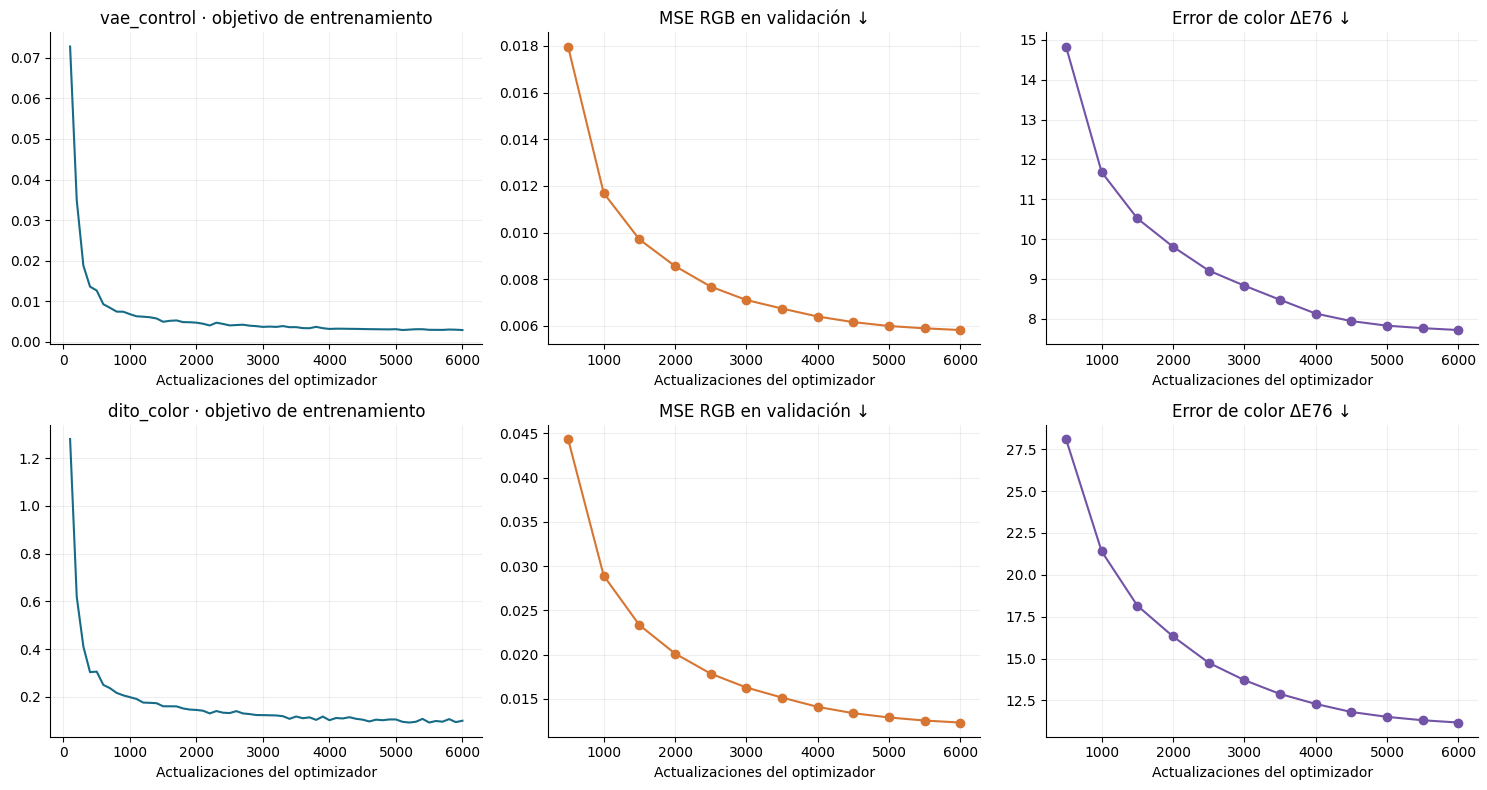

In [9]:
fig,axes=plt.subplots(len(MODELOS),3,figsize=(15,4*len(MODELOS)),squeeze=False)
for row,kind in enumerate(MODELOS):
    h=HISTORIAS[kind];v=VALIDACIONES[kind]
    for ax in axes[row]:ax.grid(alpha=.2);ax.spines[['top','right']].set_visible(False)
    axes[row,0].plot(h.step,h.loss,color='#166b87');axes[row,0].set_title(kind+' · objetivo de entrenamiento')
    axes[row,1].plot(v.step,v.mse,color='#d77532',marker='o');axes[row,1].set_title('MSE RGB en validación ↓')
    axes[row,2].plot(v.step,v.deltaE76,color='#7253a6',marker='o');axes[row,2].set_title('Error de color ΔE76 ↓')
    for ax in axes[row]:ax.set_xlabel('Actualizaciones del optimizador')
fig.tight_layout();fig.savefig(RUN/'curvas.png',dpi=150,bbox_inches='tight');plt.show()

## Test final con imágenes en pantalla

Por defecto evalúa hasta **100 estampas de test**, con sus originales y reconstrucciones de
todos los modelos. Si el test contiene menos, utiliza todas. No se usa este resultado para
escoger el ganador. El amarillo de la visualización representa piel fuera de la estampa;
no es un color aprendido del fondo transparente.

Test · vae_control:   0%|          | 0/25 [00:00<?, ?lote/s]

Test · dito_color:   0%|          | 0/25 [00:00<?, ?lote/s]

,modelo,mse,mae,psnr,ssim,deltaE76
0,vae_control,0.005429,0.038973,24.068163,0.915011,6.970047
1,dito_color,0.010181,0.051154,21.011856,0.857222,9.178318


Test fijo: 100 estampas. Ganador fijado antes del test: vae_control


Mostrando test:   0%|          | 0/10 [00:00<?, ?página/s]

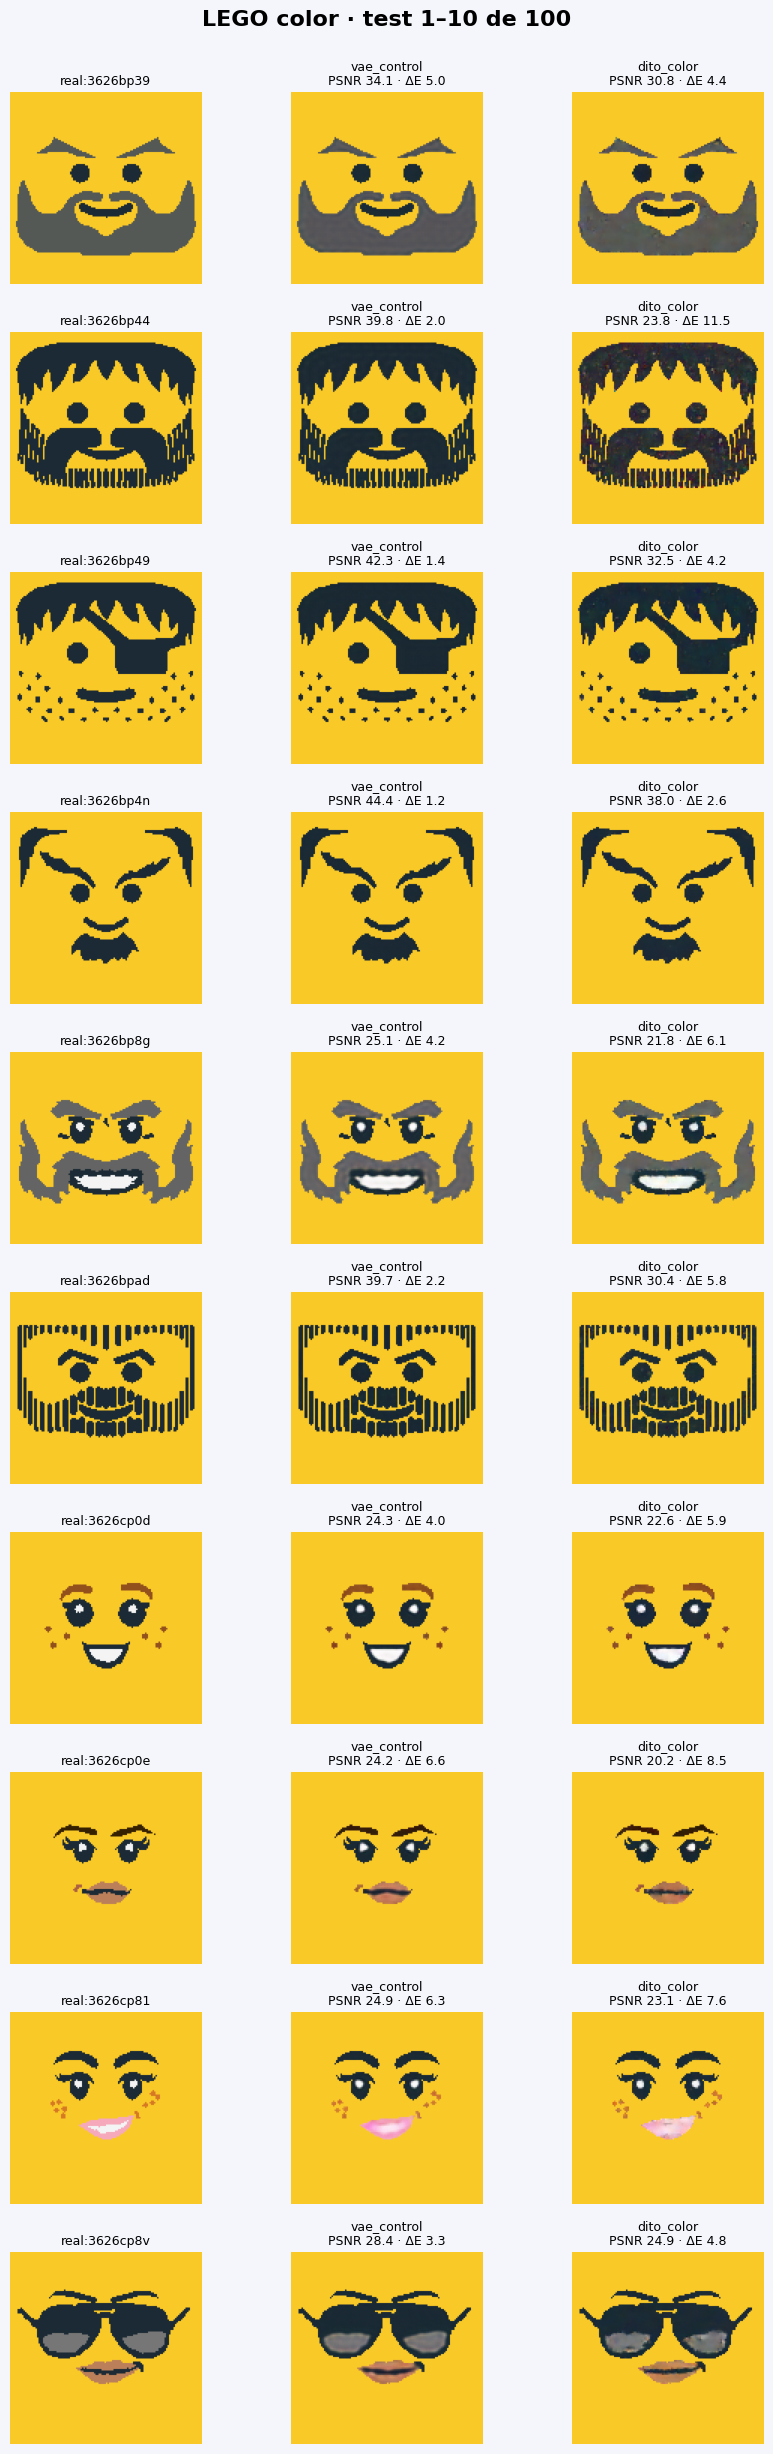

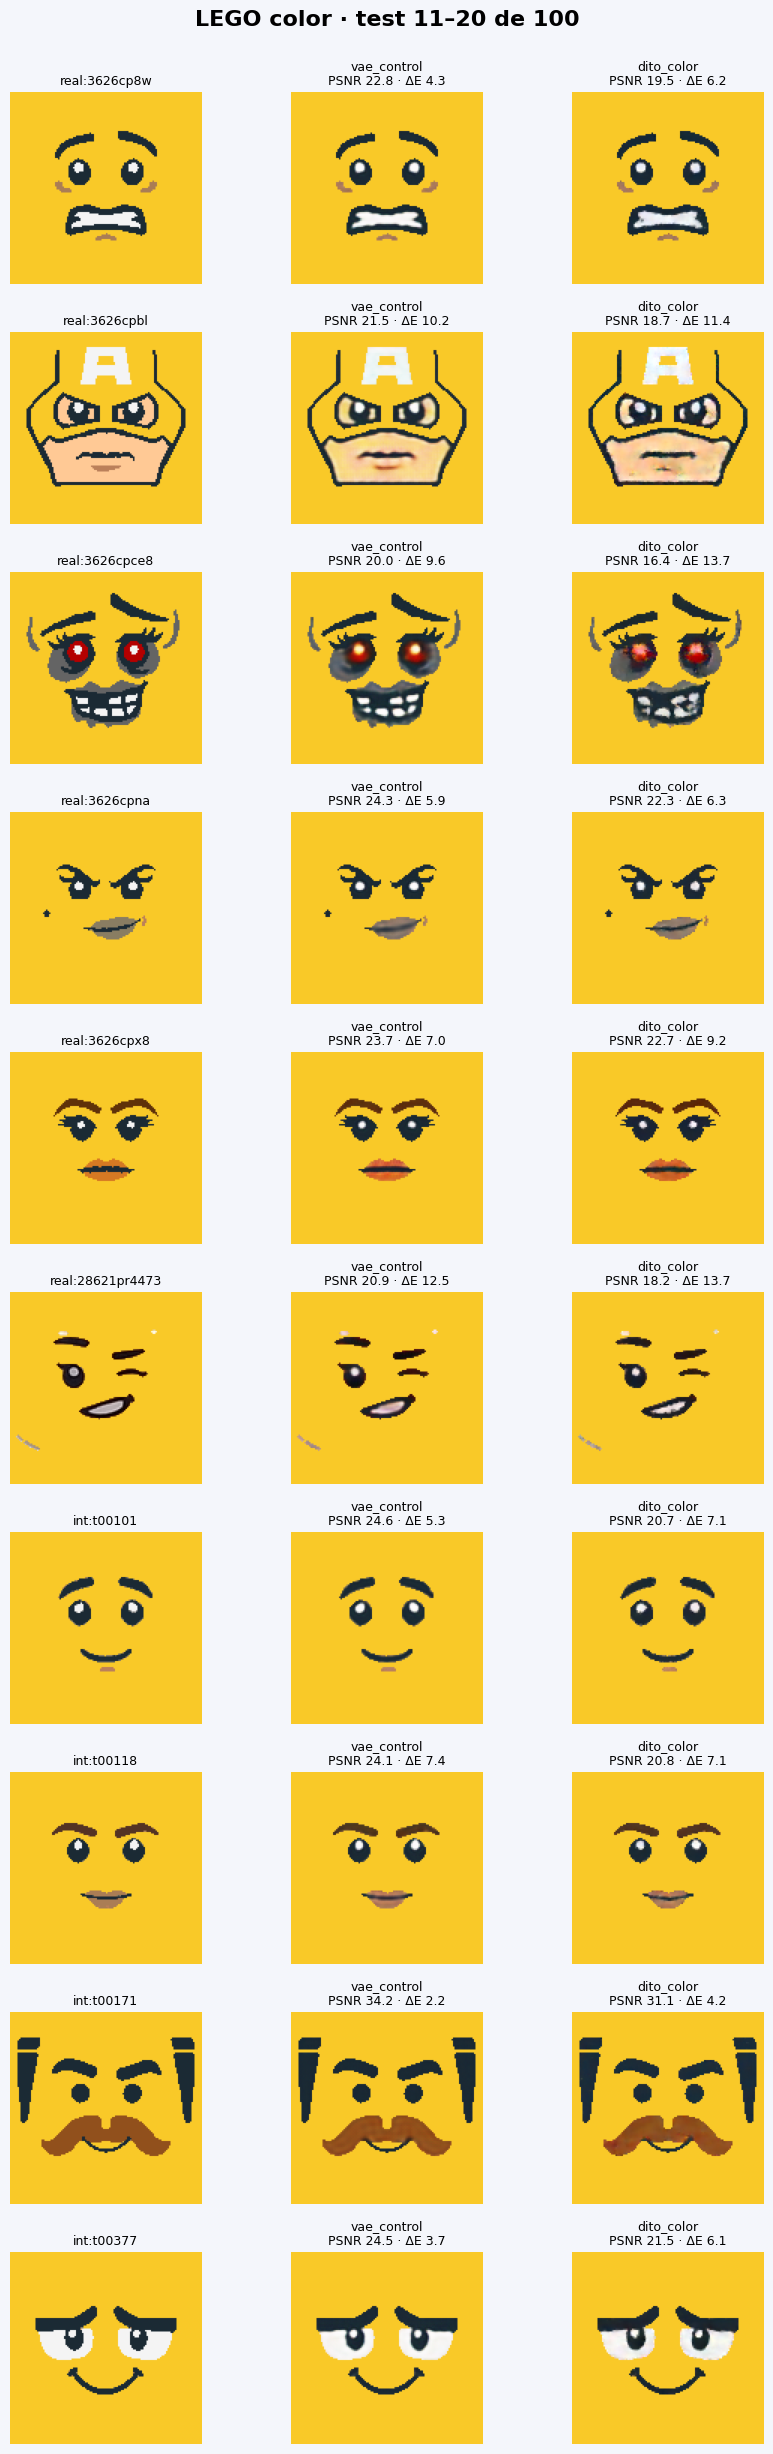

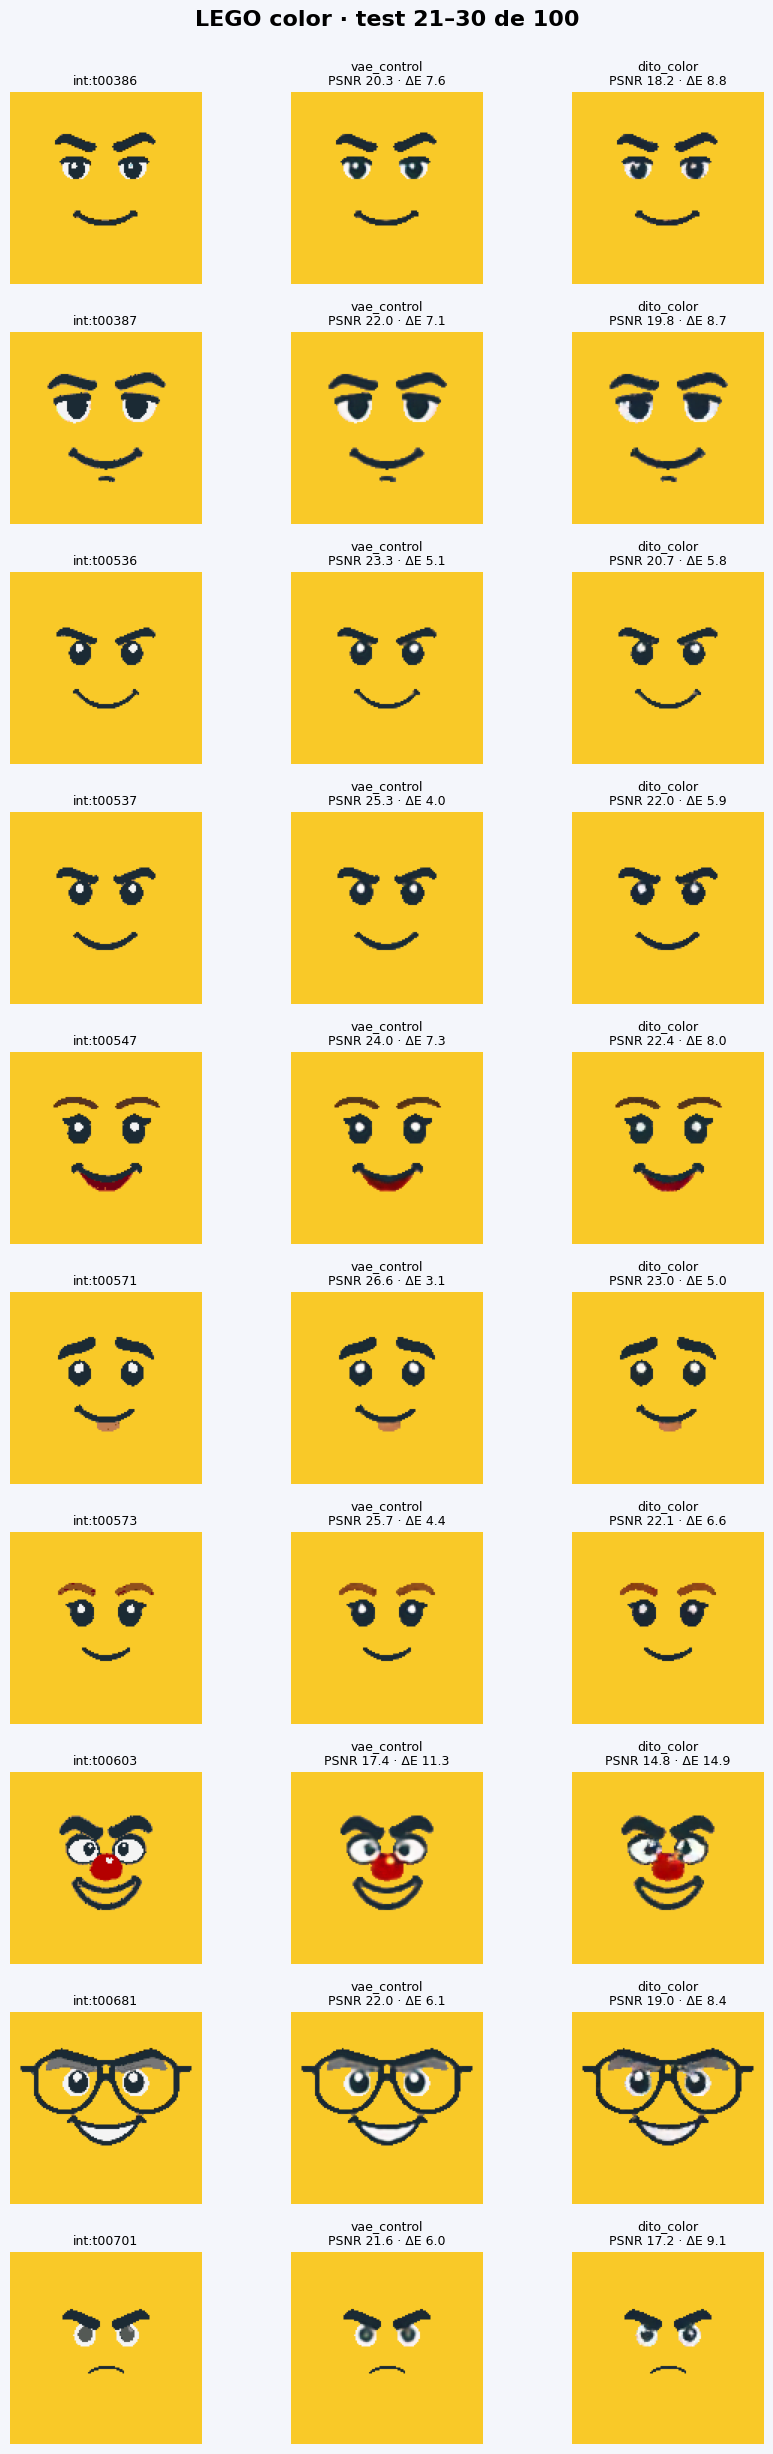

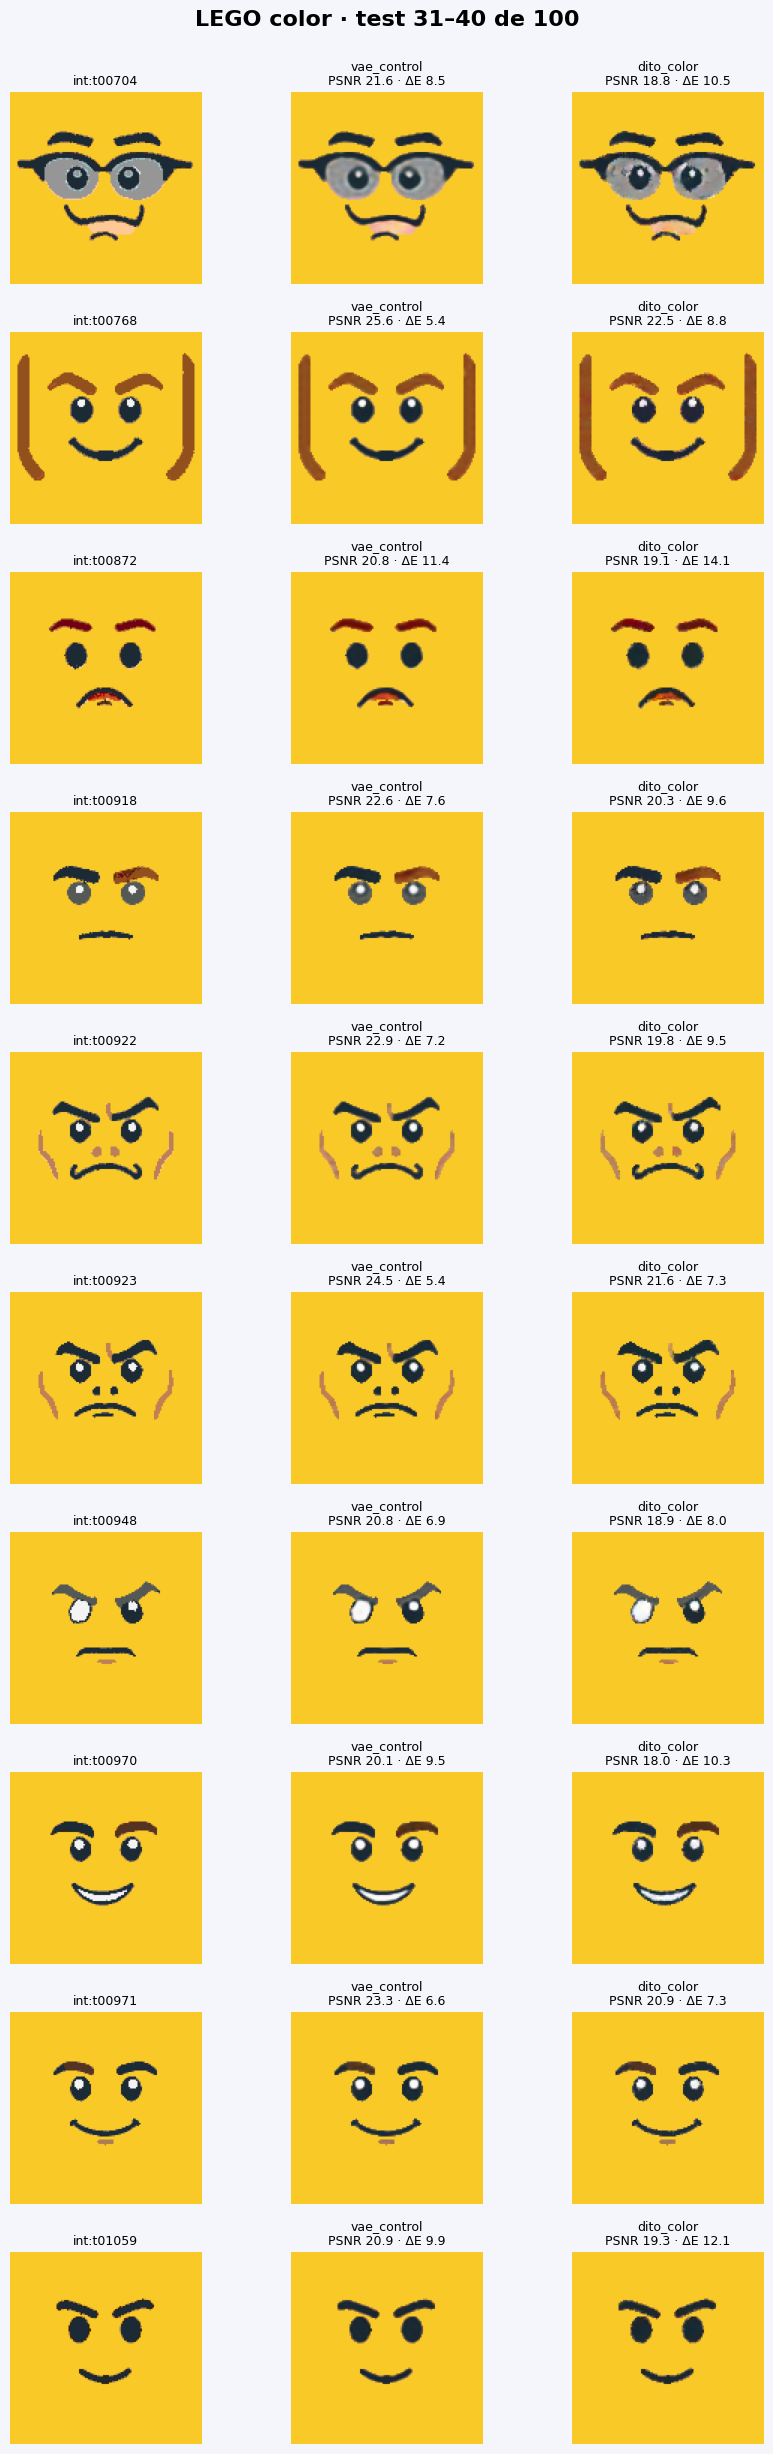

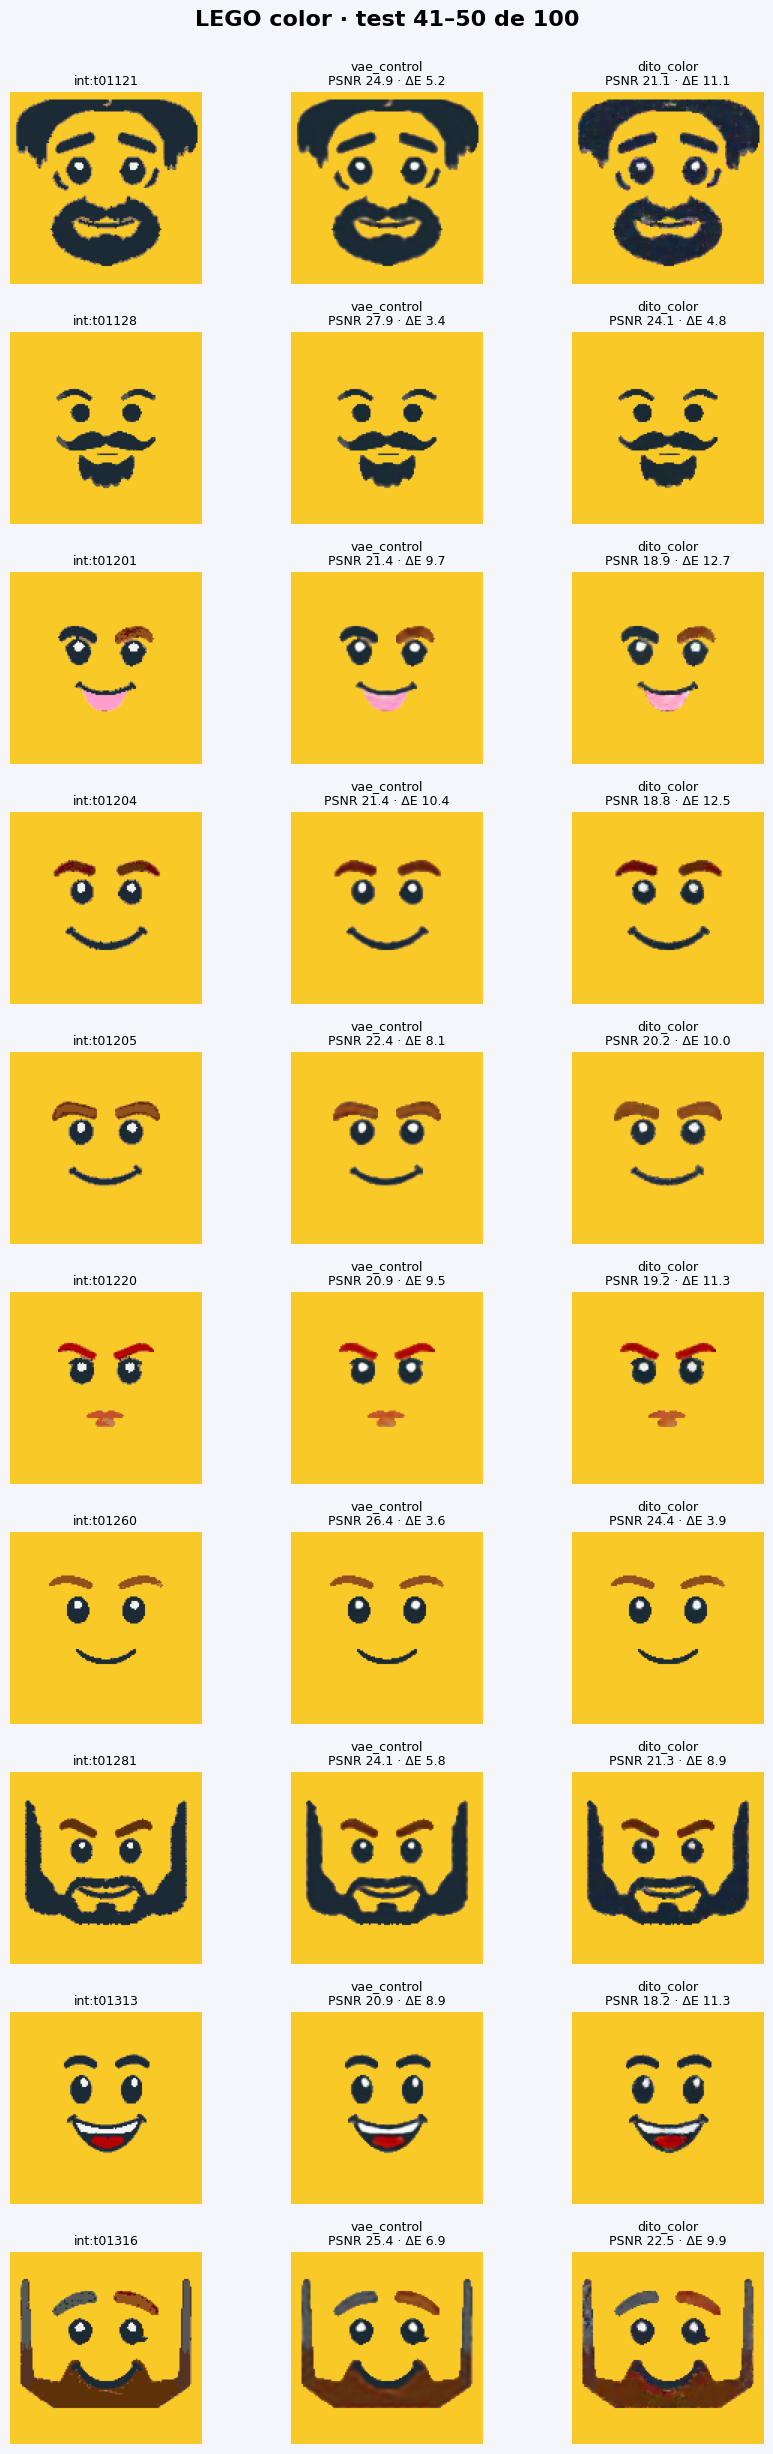

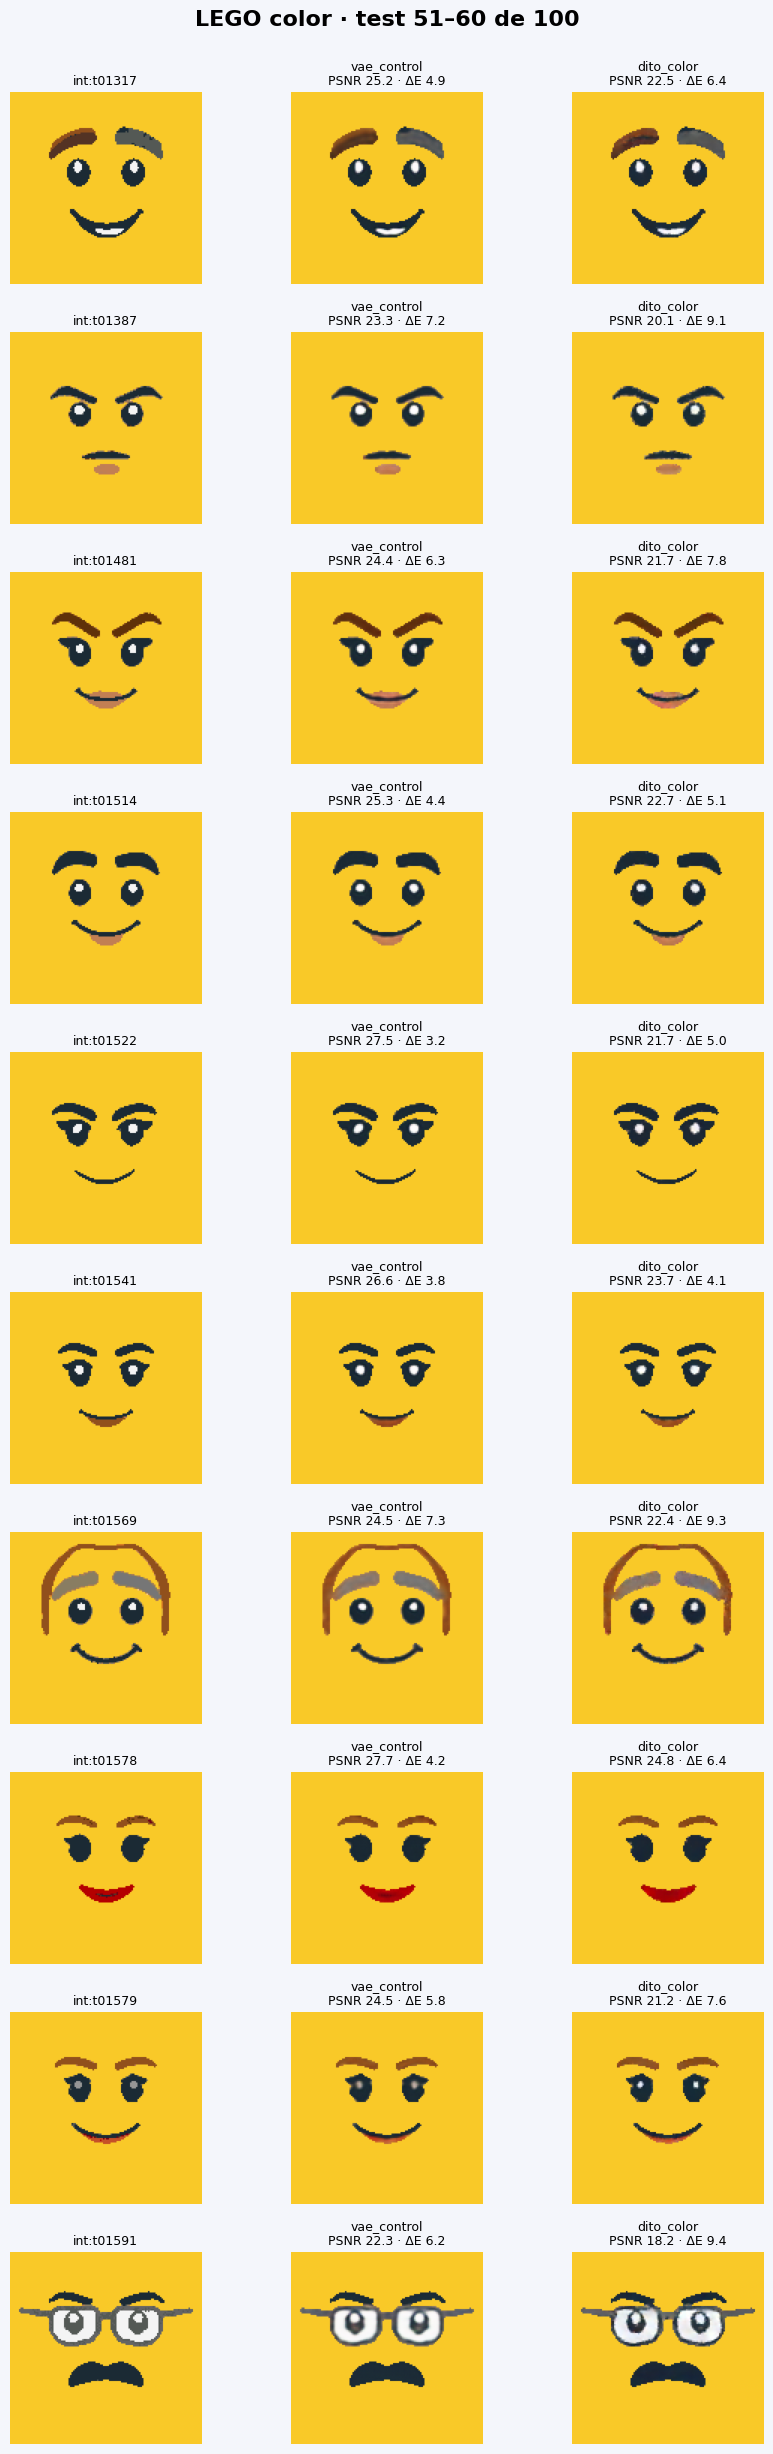

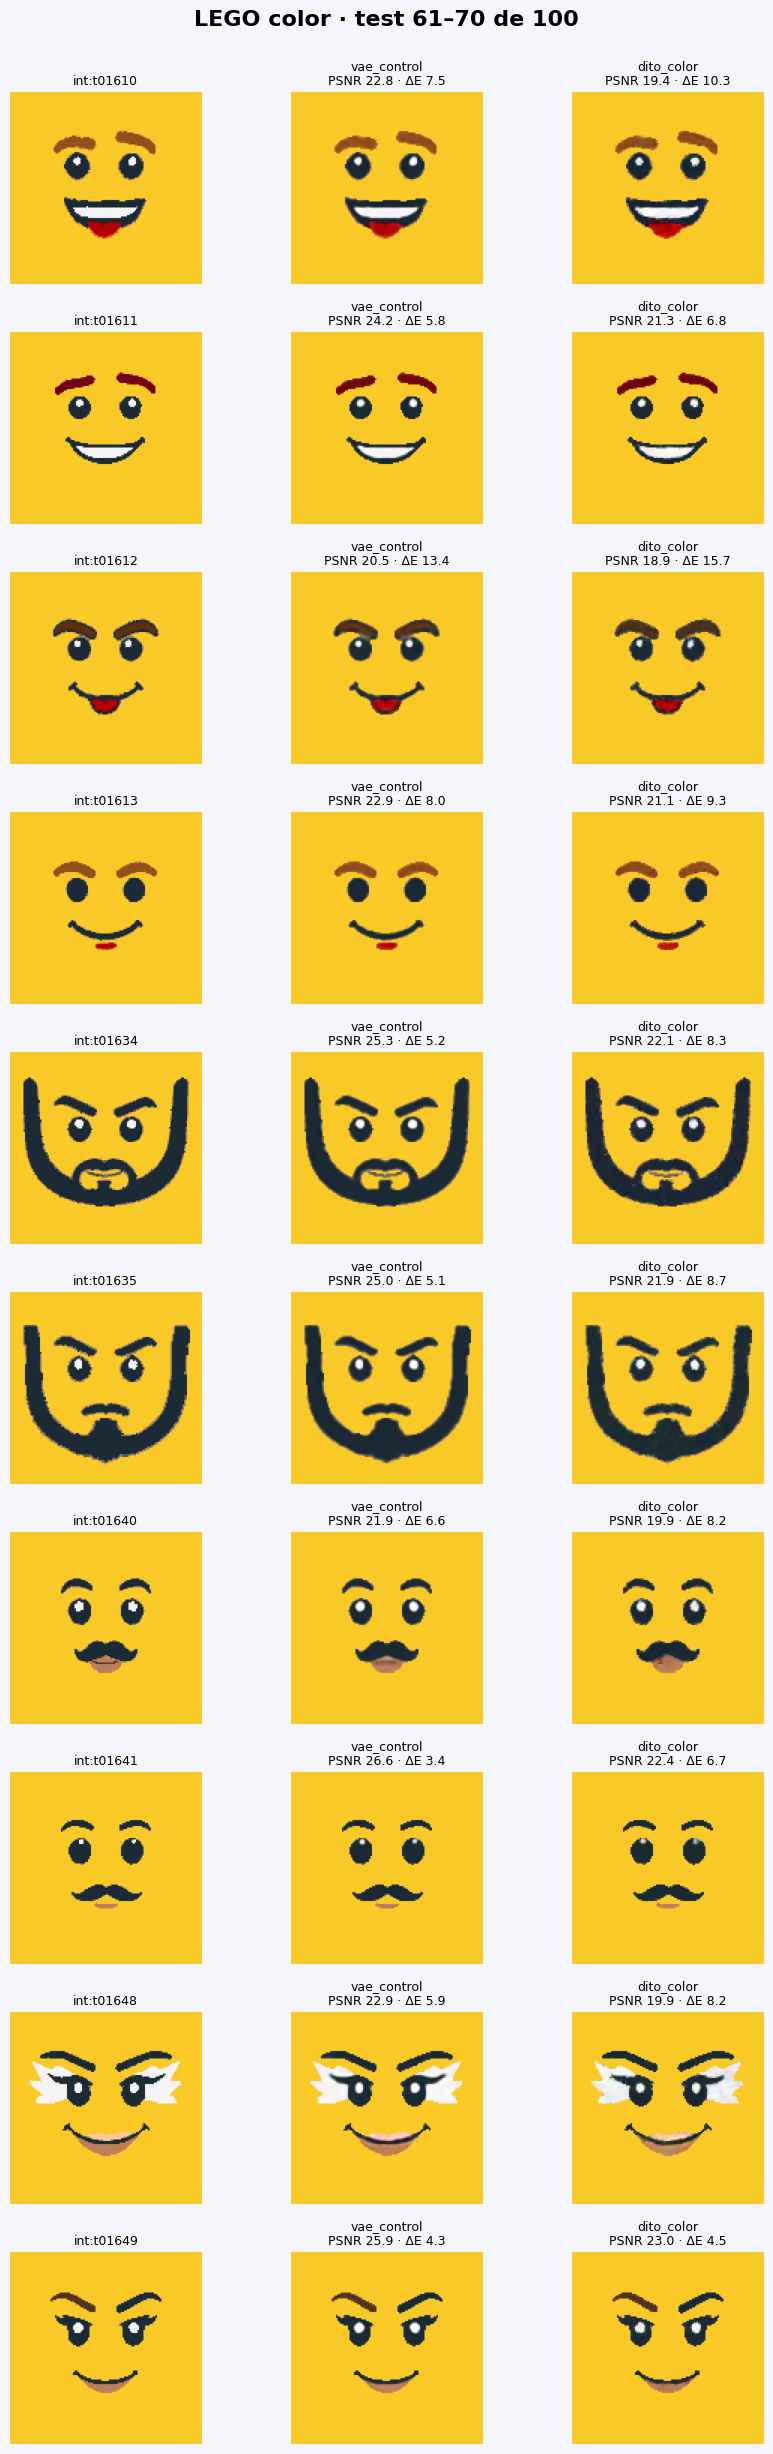

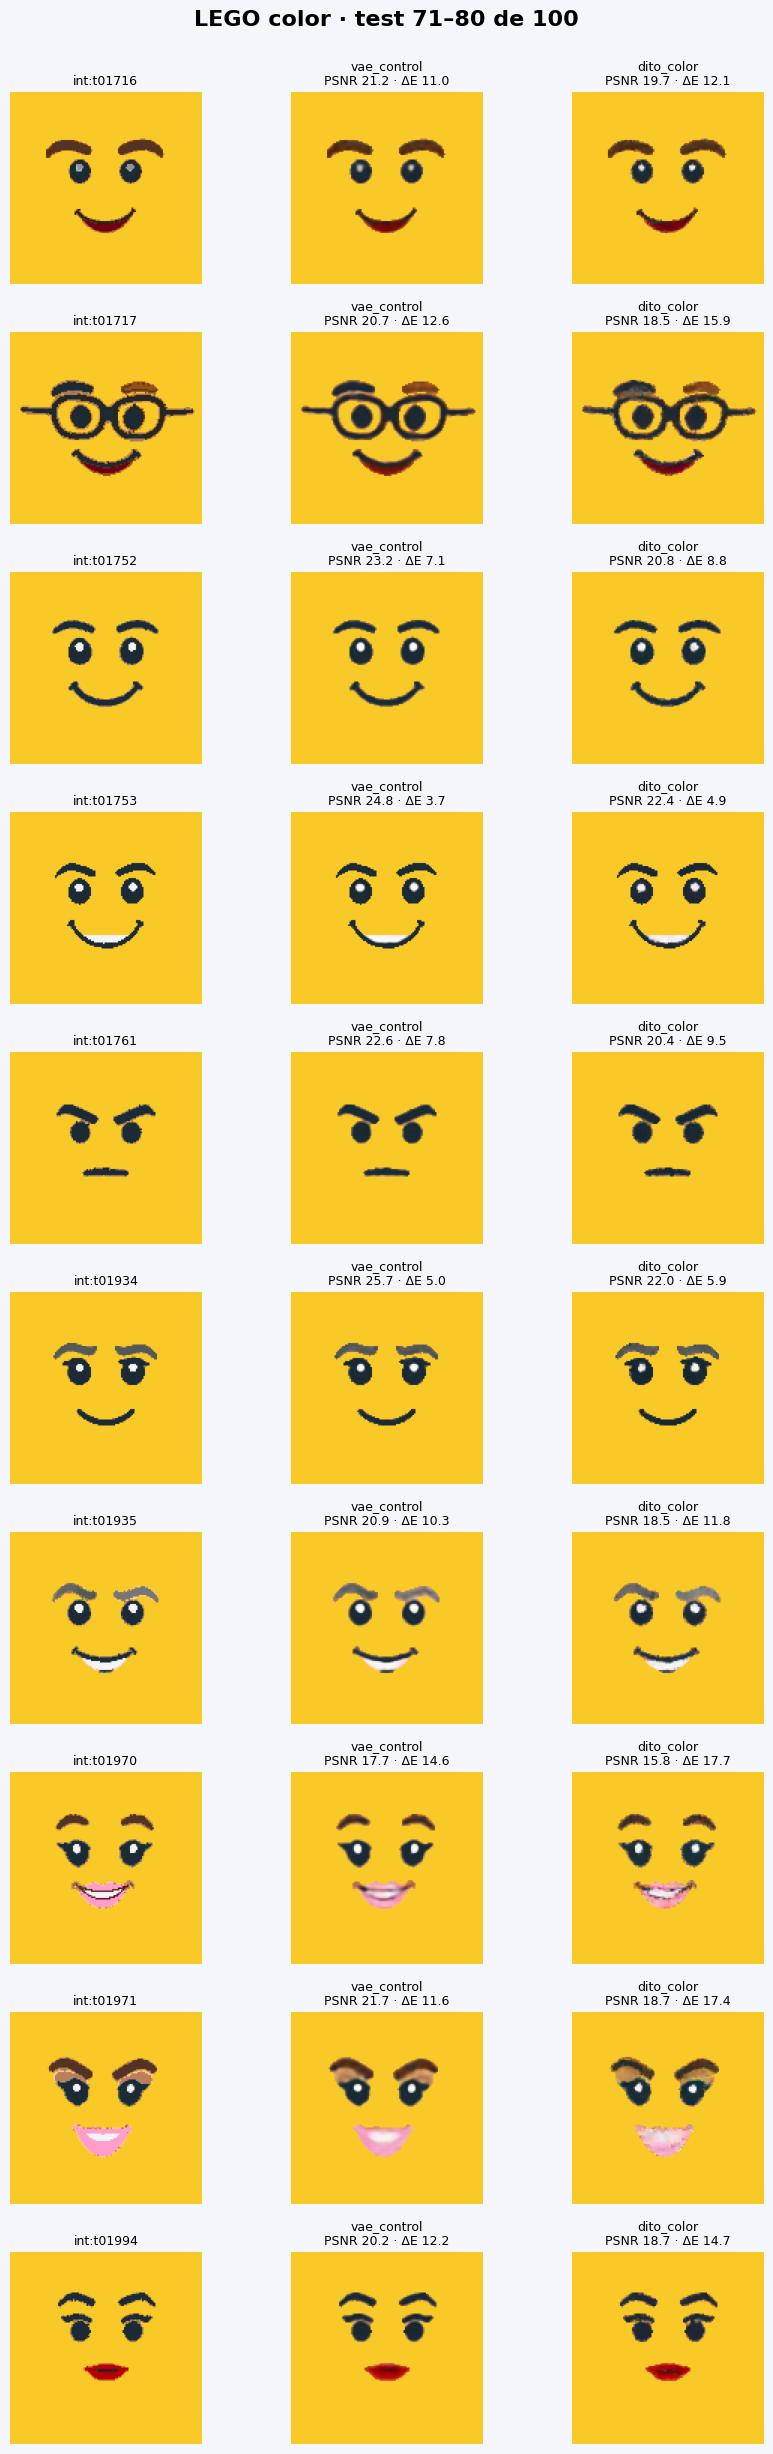

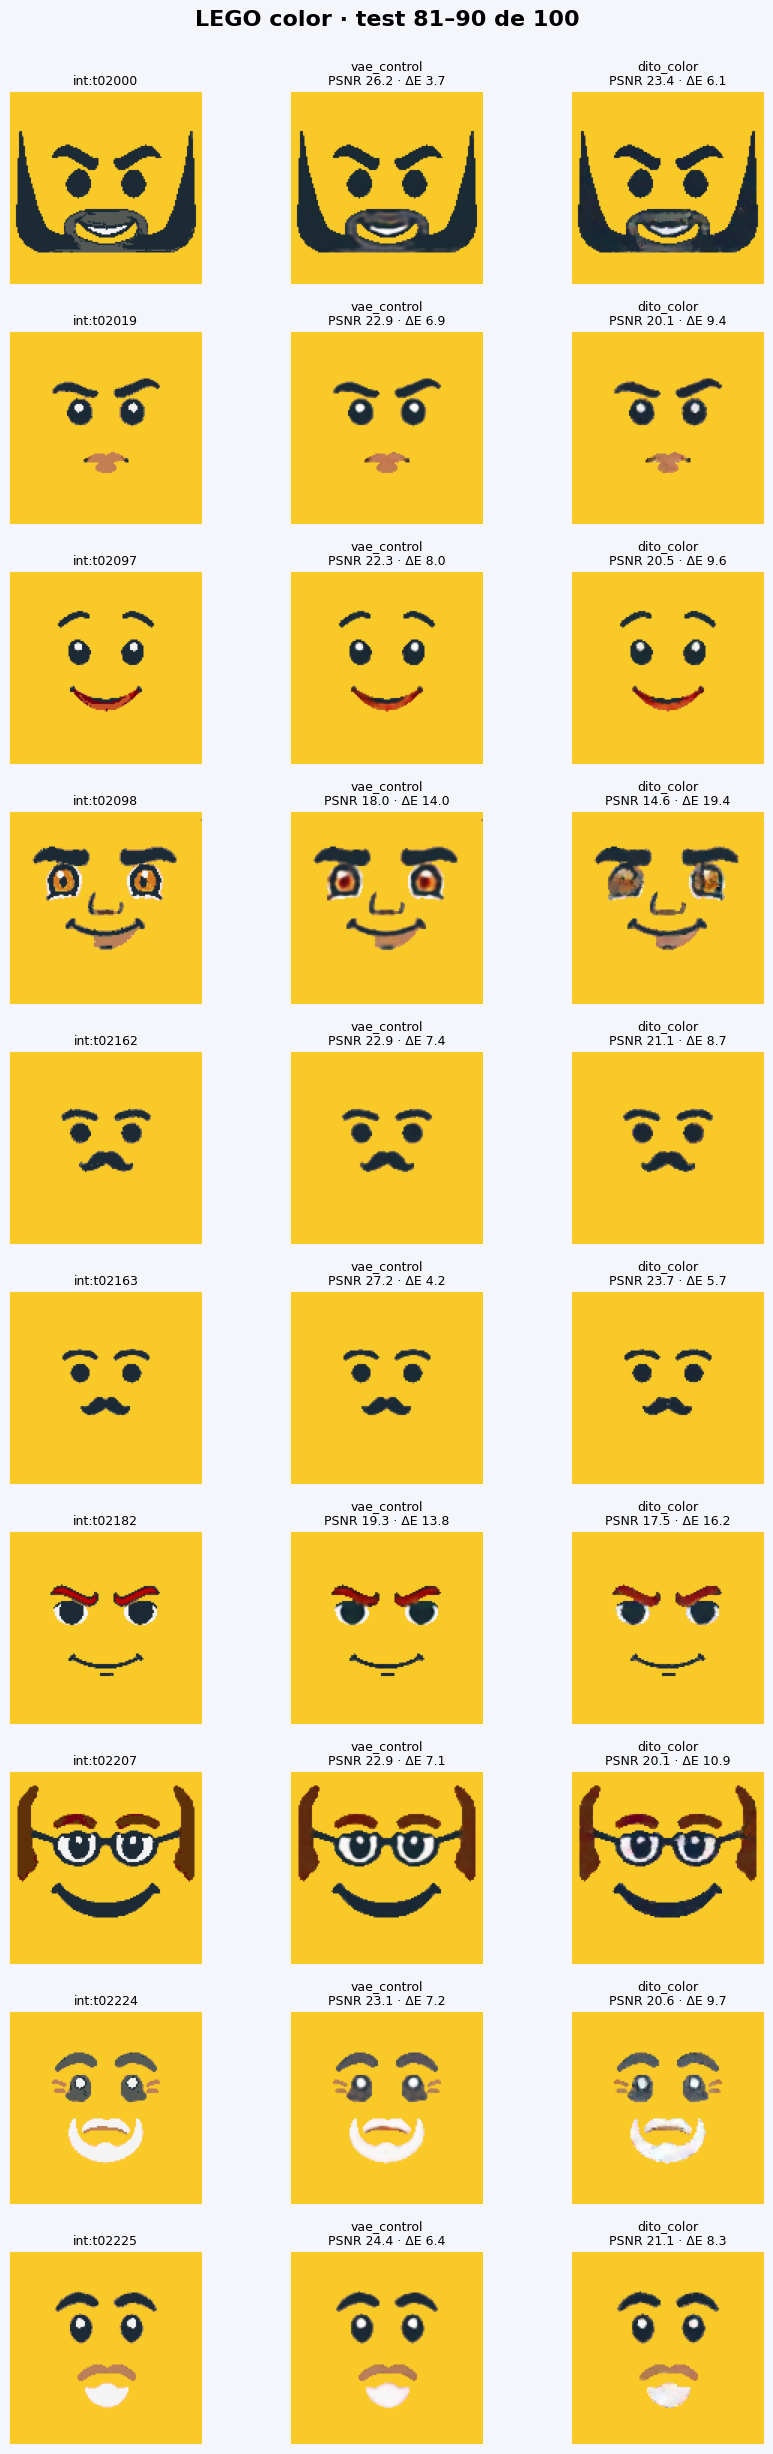

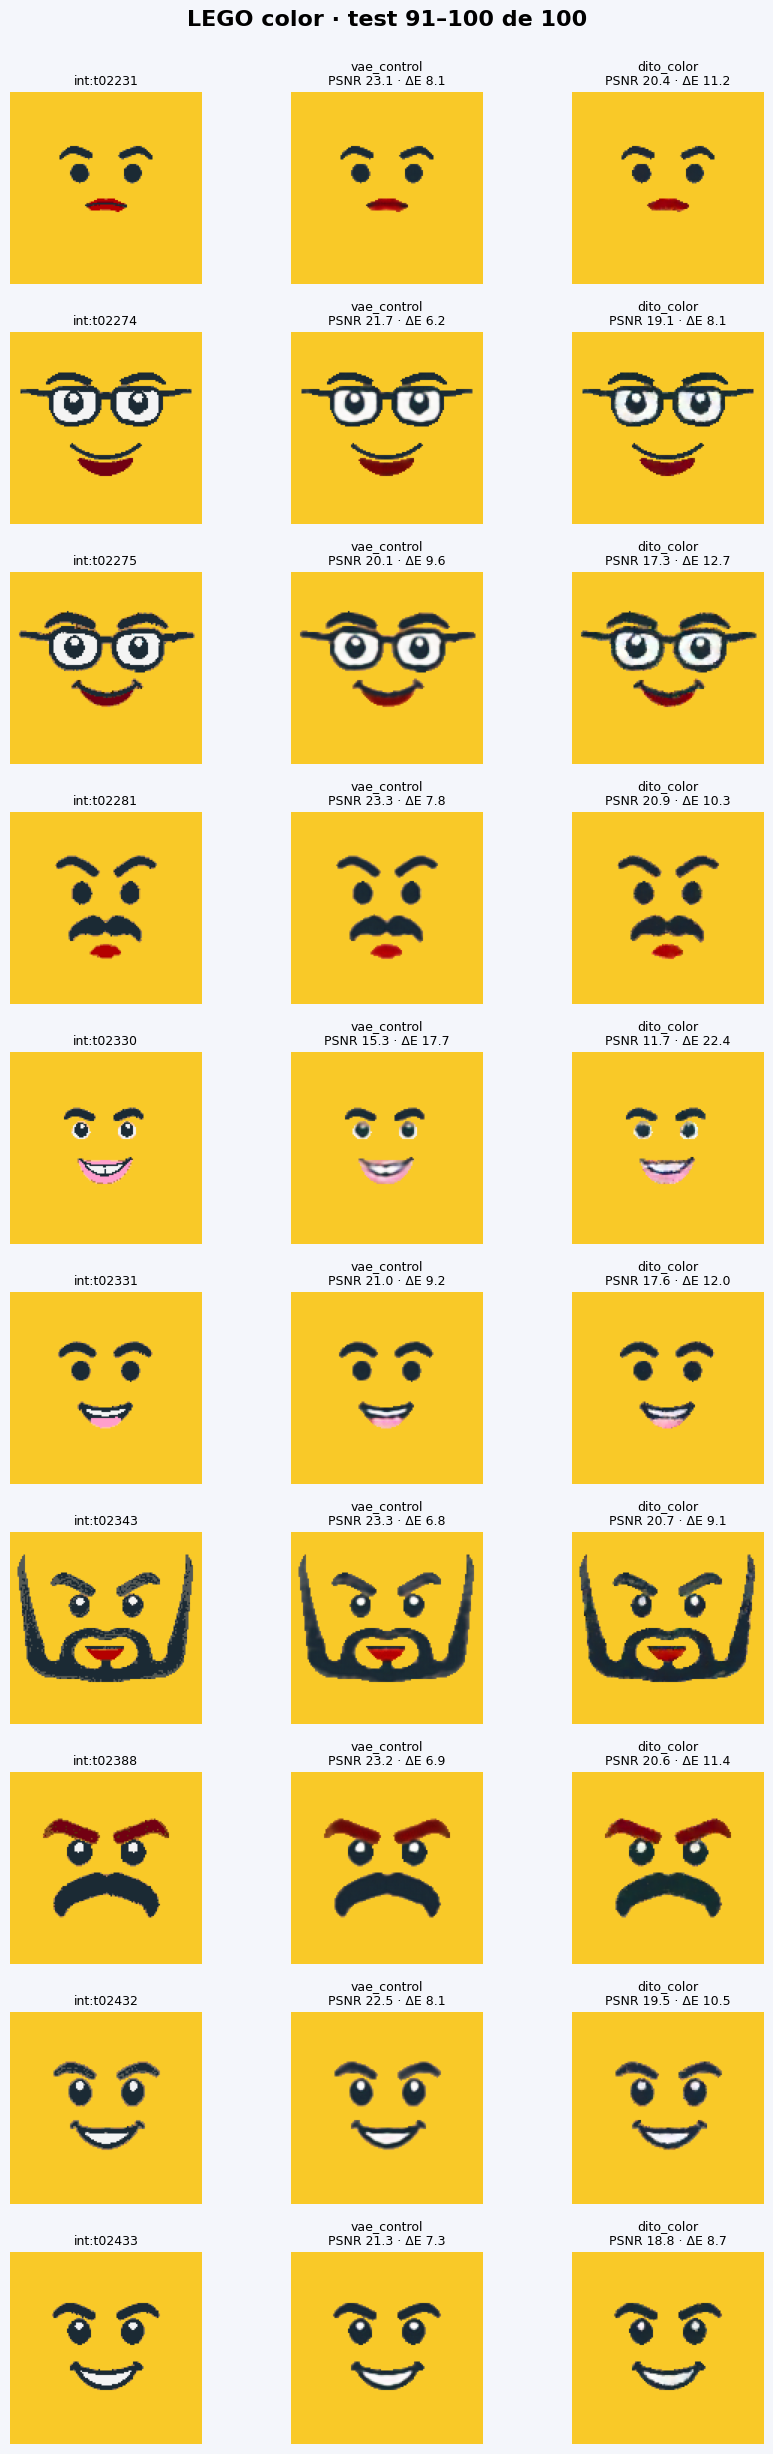

In [10]:
rng=np.random.default_rng(CONFIG['SEMILLA'])
TEST_FIXED=np.sort(rng.choice(IDX['prueba'],min(CONFIG['N_TEST'],len(IDX['prueba'])),replace=False))
RESULTADOS={};IMAGENES={}
for kind,model in MODELOS.items():
    model.to(DEVICE)
    scores,pred=evaluate(model,TEST_FIXED,steps=CONFIG['PASOS_ODE_FINAL'],
                         desc='Test · '+kind,keep_images=True)
    RESULTADOS[kind]=scores;IMAGENES[kind]=pred
    scores.to_csv(RUN/f'test_{kind}.csv',index=False);model.cpu()
comparacion=pd.DataFrame([dict(modelo=k,**d[['mse','mae','psnr','ssim','deltaE76']].mean().to_dict())
                         for k,d in RESULTADOS.items()])
display(comparacion);comparacion.to_csv(RUN/'comparacion_test.csv',index=False)
print('Test fijo:',len(TEST_FIXED),'estampas. Ganador fijado antes del test:',GANADOR)

def sobre_fondo(rgb,m):
    rgb=np.asarray(rgb);m=np.asarray(m)
    return np.clip((rgb*m+np.array([.98,.79,.16])[:,None,None]*(1-m)).transpose(1,2,0),0,1)

def mostrar_test():
    folder=RUN/'test_imagenes';folder.mkdir(exist_ok=True)
    columns=1+len(MODELOS)
    for start in tqdm(range(0,len(TEST_FIXED),CONFIG['POR_PAGINA']),desc='Mostrando test',unit='página'):
        end=min(start+CONFIG['POR_PAGINA'],len(TEST_FIXED));ids=TEST_FIXED[start:end]
        c=CARAS[torch.as_tensor(ids)].float()/255
        fig,ax=plt.subplots(len(ids),columns,figsize=(3*columns,2.5*len(ids)),squeeze=False,
                            facecolor='#f4f6fb')
        for r,i in enumerate(ids):
            m=c[r,3:4].numpy();ax[r,0].imshow(sobre_fondo(c[r,:3],m));ax[r,0].set_title(tabla.iloc[i].id,fontsize=9)
            for col,kind in enumerate(MODELOS,1):
                j=start+r;ax[r,col].imshow(sobre_fondo(IMAGENES[kind][j],m))
                score=RESULTADOS[kind].iloc[j]
                ax[r,col].set_title(f'{kind}\nPSNR {score.psnr:.1f} · ΔE {score.deltaE76:.1f}',fontsize=9)
            for a in ax[r]:a.axis('off')
        fig.suptitle(f'LEGO color · test {start+1}–{end} de {len(TEST_FIXED)}',fontsize=16,fontweight='bold')
        fig.tight_layout(rect=[0,0,1,.98]);fig.savefig(folder/f'test_{start+1:03d}_{end:03d}.png',dpi=120)
        plt.show();plt.close(fig)
mostrar_test()

## ¿El código contiene color o el decoder lo ignora?

Prueba código correcto, código cero, código de otra cara y ruido calibrado con estadísticas
de train. La máscara y el ruido del decoder permanecen iguales. Barajar códigos entre formas
distintas mezcla color y compatibilidad geométrica: es una sonda, no una prueba aislada de color.
Una prueba más fuerte es usar estampas de alfa idéntico y color distinto, cuando existan.

In [11]:
@torch.no_grad()
def latent_stats(model):
    model.eval();summ=None;sumsq=None;count=0.
    idx=IDX['entrenamiento']
    for j in tqdm(range(0,len(idx),CONFIG['LOTE_EVAL']),desc='Estadísticas z · solo train',unit='lote',leave=False):
        c=batch(idx[j:j+CONFIG['LOTE_EVAL']]);m=c[:,3:4]
        with amp_ctx():z=model.encode(c[:,:3],m).float()
        a=celdas_activas(m);s=(z*a).sum((0,2,3)).double().cpu();sq=(z.square()*a).sum((0,2,3)).double().cpu()
        summ=s if summ is None else summ+s;sumsq=sq if sumsq is None else sumsq+sq;count+=float(a.sum().cpu())
    mean=summ/count;std=(sumsq/count-mean.square()).clamp_min(1e-8).sqrt()
    return dict(media=mean.float(),desv=std.float(),n_celdas_activas=count,
                normalizacion='por_canal_solo_train',manifest_sha=MANIFEST_SHA)

STATS={}
for kind,model in MODELOS.items():
    model.to(DEVICE);STATS[kind]=latent_stats(model);model.cpu()

ABLACIONES=[]
for kind,model in MODELOS.items():
    model.to(DEVICE).eval();ids=TEST_FIXED[:CONFIG['N_ABLACION']]
    terms={name:[] for name in ['correcto','cero','barajado','ruido_0.25']}
    c=batch(ids);m=c[:,3:4];rgb=c[:,:3]
    with torch.no_grad(),amp_ctx():z=model.encode(rgb,m).float()
    shift=torch.roll(torch.arange(len(ids),device=DEVICE),1)
    g=torch.Generator().manual_seed(CONFIG['SEMILLA']+995)
    eta=torch.randn(z.shape,generator=g).to(DEVICE)
    std=STATS[kind]['desv'].to(DEVICE)[None,:,None,None]
    alternatives={'correcto':z,'cero':torch.zeros_like(z),'barajado':z[shift],
                  'ruido_0.25':z+.25*std*eta*celdas_activas(m)}
    for name,za in tqdm(alternatives.items(),desc='Sondas de latente · '+kind,unit='sonda'):
        collected=[]
        for j in range(0,len(ids),CONFIG['LOTE_EVAL']):
            sl=slice(j,j+CONFIG['LOTE_EVAL'])
            with torch.no_grad(),amp_ctx():
                y=model.decode(za[sl],m[sl],[CONFIG['SEMILLA']+int(i) for i in ids[sl]],CONFIG['PASOS_ODE_FINAL'])
            scores=metricas(rgb[sl],y,m[sl]);collected.append({k:v.cpu() for k,v in scores.items()})
        ABLACIONES.append(dict(modelo=kind,sonda=name,n=len(ids),
                               **{k:float(torch.cat([s[k] for s in collected]).mean()) for k in collected[0]}))
    del c,m,rgb,z,alternatives,za,eta;model.cpu()
ablation=pd.DataFrame(ABLACIONES);display(ablation);ablation.to_csv(RUN/'ablacion_latente.csv',index=False)

Estadísticas z · solo train:   0%|          | 0/528 [00:00<?, ?lote/s]

Estadísticas z · solo train:   0%|          | 0/528 [00:00<?, ?lote/s]

Sondas de latente · vae_control:   0%|          | 0/4 [00:00<?, ?sonda/s]

Sondas de latente · dito_color:   0%|          | 0/4 [00:00<?, ?sonda/s]

,modelo,sonda,n,mse,mae,psnr,ssim,deltaE76
0,vae_control,correcto,16,0.003400,0.026956,28.779747,0.939992,5.350343
1,vae_control,cero,16,0.069147,0.197400,12.295349,0.459418,36.302799
2,vae_control,barajado,16,0.083110,0.187847,11.900227,0.472995,29.244488
3,vae_control,ruido_0.25,16,0.004591,0.034017,26.254608,0.901962,6.359918
4,dito_color,correcto,16,0.006890,0.039333,24.130970,0.883749,7.626445
5,dito_color,cero,16,0.077529,0.193307,12.040689,0.373098,33.202904
6,dito_color,barajado,16,0.097254,0.231803,10.514283,0.308701,36.823273
7,dito_color,ruido_0.25,16,0.009159,0.048996,21.831882,0.834270,9.138533


## Recorridos de color con máscara fija

Se priorizan pares con alfa idéntico y color distinto. Si no existen suficientes, se usan
geometrías cercanas y se indica expresamente. Se mantiene la máscara de A y una misma semilla
de ruido en todo el recorrido. Estos códigos se obtienen de test y se usan solo para visualizar.

Interpolando colores:   0%|          | 0/3 [00:00<?, ?par/s]

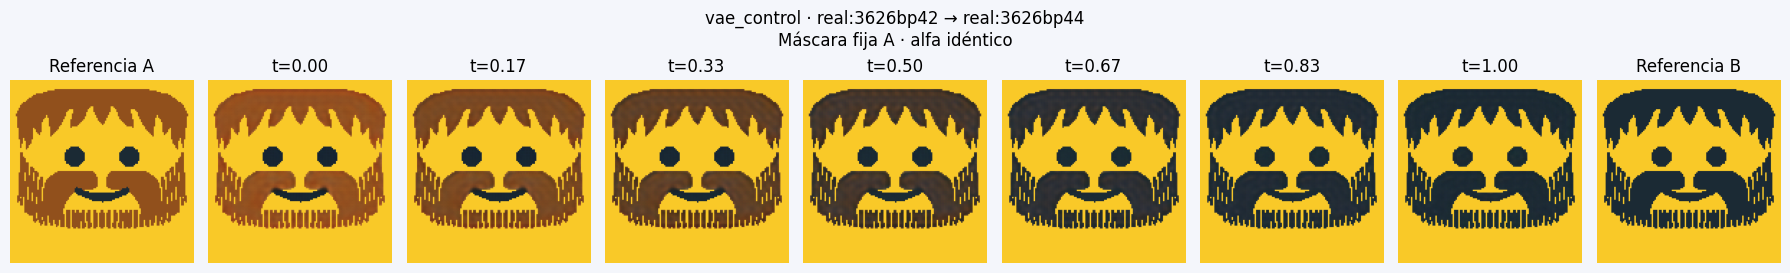

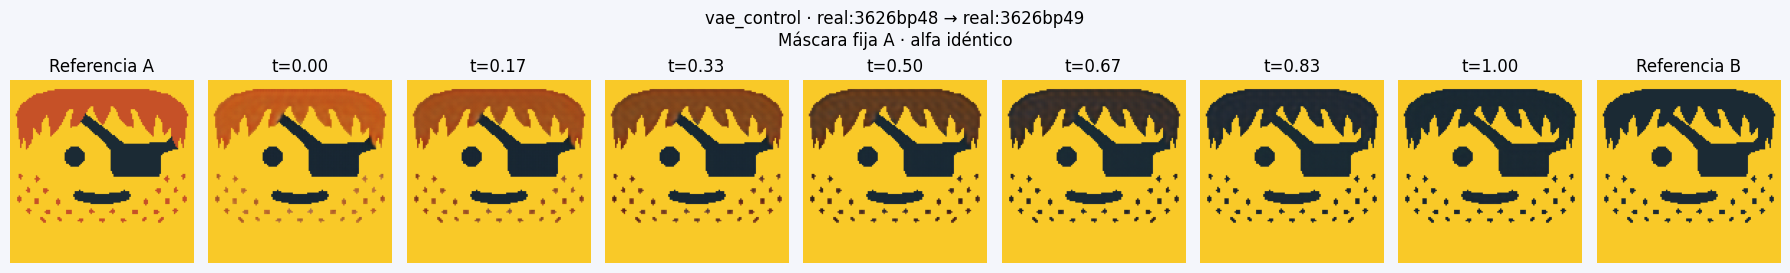

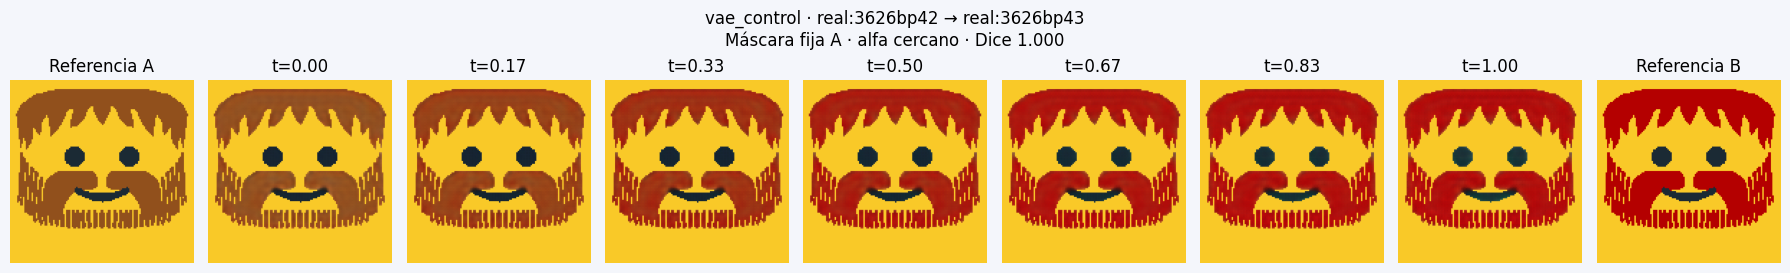

In [12]:
def pares_color(indices,n):
    ids=list(map(int,indices));pairs=[];used=set()
    for sha,g in tabla.iloc[ids].groupby('sha_mask'):
        if len(g)>1:
            ii=list(g.index);a,b=ii[0],ii[-1];pairs.append((a,b,'alfa idéntico'));used.add((a,b))
            if len(pairs)==n:return pairs
    # Vecinos por Dice en alfa. El target sigue siendo el RGB propio de cada estampa.
    if len(ids)>1:
        masks=CARAS[torch.as_tensor(ids),3].float().flatten(1)/255
        sums=masks.sum(1);dice=2*(masks@masks.T)/(sums[:,None]+sums[None,:]).clamp_min(1)
        dice.fill_diagonal_(-1)
        for _ in range(n*4):
            flat=int(dice.argmax());a,b=divmod(flat,len(ids));score=float(dice[a,b]);dice[a,b]=dice[b,a]=-1
            if score<0:break
            pair=(min(ids[a],ids[b]),max(ids[a],ids[b]))
            if pair not in used:
                pairs.append((*pair,f'alfa cercano · Dice {score:.3f}'));used.add(pair)
                if len(pairs)>=n:break
    return pairs

@torch.no_grad()
def mostrar_interpolaciones_color(model,pares,n_pasos=7):
    model.to(DEVICE).eval()
    for a,b,label in tqdm(pares,desc='Interpolando colores',unit='par'):
        c=batch([a,b]);m=c[:1,3:4]
        with amp_ctx():z=model.encode(c[:,:3],c[:,3:4]).float()
        ts=torch.linspace(0,1,n_pasos,device=DEVICE)
        path=z[:1]+ts[:,None,None,None]*(z[1:2]-z[:1])
        ys=[]
        for j in range(0,n_pasos,CONFIG['LOTE_EVAL']):
            zz=path[j:j+CONFIG['LOTE_EVAL']];mm=m.expand(len(zz),-1,-1,-1)
            with amp_ctx():ys.append(model.decode(zz,mm,[CONFIG['SEMILLA']]*len(zz),CONFIG['PASOS_ODE_FINAL']).cpu())
        ys=torch.cat(ys);mask=m.cpu().numpy()[0]
        fig,axes=plt.subplots(1,n_pasos+2,figsize=(2*(n_pasos+2),2.8),facecolor='#f4f6fb')
        axes[0].imshow(sobre_fondo(c[0,:3].cpu(),mask));axes[0].set_title('Referencia A')
        for j,t in enumerate(ts.cpu()):
            axes[j+1].imshow(sobre_fondo(ys[j],mask));axes[j+1].set_title(f't={float(t):.2f}')
        axes[-1].imshow(sobre_fondo(c[1,:3].cpu(),c[1,3:4].cpu()));axes[-1].set_title('Referencia B')
        for ax in axes:ax.axis('off')
        fig.suptitle(f'{model.kind} · {tabla.iloc[a].id} → {tabla.iloc[b].id}\nMáscara fija A · {label}',fontsize=12)
        fig.tight_layout();fig.savefig(RUN/f'interpolacion_{model.kind}_{a}_{b}.png',dpi=120);plt.show();plt.close(fig)
    model.cpu()

model=MODELOS[GANADOR]
mostrar_interpolaciones_color(model,pares_color(IDX['prueba'],CONFIG['N_INTERPOLACIONES']))

## Exportar para el Flow 2

El ZIP contiene el **mejor decoder y encoder EMA**, su configuración, código y fuentes,
estadísticas de train, banco de códigos, manifiestos y alias por pieza. El banco contiene
val/test etiquetados para evaluación: **el Flow 2 deberá entrenar solo con train**.
La exportación usa el codec congelado; no usa las fotos humanas.

También se conservan `runs/*/best.pt` y `last.pt` en la salida completa para poder reanudar.
La selección final se hace con validación, no con el test mostrado.

In [13]:
EXPORT=RUN/'para_flow2';EXPORT.mkdir(exist_ok=True)
# El mismo código ejecutado arriba, con imports y setup para cargarlo en otra libreta.
header="""import sys, importlib.util
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
UP=Path(__file__).resolve().parent/'upstream_color'
if str(UP) not in sys.path:sys.path.insert(0,str(UP))
def load_module(name,path):
    spec=importlib.util.spec_from_file_location(name,path)
    mod=importlib.util.module_from_spec(spec);spec.loader.exec_module(mod);return mod
codec=load_module('export_color_codec',UP/'codec.py')
renderer=load_module('export_color_renderer',UP/'renderer.py')
fm_module=load_module('export_color_fm',UP/'fm.py')
sampler_module=load_module('export_color_samplers',UP/'samplers.py')
"""
loader="""
def cargar_color(checkpoint,device='cpu'):
    ck=torch.load(checkpoint,map_location='cpu',weights_only=False)
    if ck.get('artifact_role')!='lego_color_codec':raise ValueError('No es un checkpoint de color exportado')
    model=build_model(ck['kind'],ck['config'])
    model.load_state_dict(ck['ema'],strict=True)
    return model.to(device).eval().requires_grad_(False),ck

def estandarizar(z,m,stats):
    mean=stats['media'].to(z)[None,:,None,None];std=stats['desv'].to(z)[None,:,None,None]
    return ((z-mean)/std)*celdas_activas(m)
def desestandarizar(z,m,stats):
    mean=stats['media'].to(z)[None,:,None,None];std=stats['desv'].to(z)[None,:,None,None]
    return (z*std+mean)*celdas_activas(m)
"""
(EXPORT/'color_codec.py').write_text(header+MODEL_SOURCE+'\n'+loader)
up=EXPORT/'upstream_color';up.mkdir(exist_ok=True)
for p in UP.iterdir():
    if p.is_file():(up/p.name).write_bytes(p.read_bytes())
registros.to_csv(EXPORT/'manifest_color_aliases.csv',index=False)
tabla.to_csv(EXPORT/'manifest_color.csv',index=False)
for kind,model in MODELOS.items():
    model.to(DEVICE).eval();zs=[];acts=[]
    for j in tqdm(range(0,len(tabla),CONFIG['LOTE_EVAL']),desc='Exportando códigos · '+kind,unit='lote'):
        c=batch(np.arange(j,min(j+CONFIG['LOTE_EVAL'],len(tabla))));m=c[:,3:4]
        with torch.no_grad(),amp_ctx():zs.append(model.encode(c[:,:3],m).float().cpu())
        acts.append(celdas_activas(m).cpu())
    z=torch.cat(zs);active=torch.cat(acts).to(torch.uint8)
    ck=torch.load(RUN/'runs'/kind/'best.pt',map_location='cpu',weights_only=False)
    export=dict(kind=kind,config=CONFIG,ema={k:v.detach().cpu() for k,v in model.state_dict().items()},
                stats=STATS[kind],manifest_sha=MANIFEST_SHA,core_sha=CORE_SHA,
                step_best=ck['step'],mse_val_best=ck['best_mse'],
                artifact_role='lego_color_codec',seleccion='validacion_mse',
                geometry='128x128_centrado_sin_redimensionar',piel='transparente_material_3d_aparte')
    atomic_save(export,EXPORT/f'{kind}.pt')
    atomic_save(STATS[kind],EXPORT/f'estadisticas_{kind}.pt')
    np.savez_compressed(EXPORT/f'latentes_{kind}.npz',z=z.numpy(),activas=active.numpy(),
        color_i=tabla.color_i.to_numpy(),id=tabla.id.to_numpy(dtype=str),
        particion=tabla.particion.to_numpy(dtype=str),manifest_sha=np.array(MANIFEST_SHA))
    model.cpu();del zs,acts,z,active,ck

(EXPORT/'seleccion.json').write_text(json.dumps(dict(ganador=GANADOR,checkpoint=f'{GANADOR}.pt',
      manifest_sha=MANIFEST_SHA,core_sha=CORE_SHA,criterio='MSE de validación; no seleccionado con test',
      steps_val=CONFIG['PASOS_ODE_VAL'],steps_final=CONFIG['PASOS_ODE_FINAL'],smoke=CONFIG['SMOKE']),indent=2))

# Comprobar que el paquete se importa de forma independiente y reproduce la salida.
exported=load_module('color_codec_export_test',EXPORT/'color_codec.py')
reloaded,ck=exported.cargar_color(EXPORT/f'{GANADOR}.pt',DEVICE)
ii=TEST_FIXED[:1];c=batch(ii);rgb,m=c[:,:3],c[:,3:4]
original=MODELOS[GANADOR].to(DEVICE).eval()
seeds=[CONFIG['SEMILLA']+int(i) for i in ii]
with torch.no_grad(),amp_ctx():
    a=original.reconstruct(rgb,m,seeds,CONFIG['PASOS_ODE_FINAL'])
    b=reloaded.reconstruct(rgb,m,seeds,CONFIG['PASOS_ODE_FINAL'])
assert torch.allclose(a,b,atol=2e-5), 'La exportación no reproduce el modelo'
original.cpu();reloaded.cpu();del original,reloaded,c,rgb,m,a,b

zip_path=RUN/'lego_color_para_Flow2.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as zf:
    for p in tqdm(sorted(EXPORT.rglob('*')),desc='Empaquetando para Flow 2',unit='archivo'):
        if p.is_file() and '__pycache__' not in p.parts:zf.write(p,Path('para_flow2')/p.relative_to(EXPORT))
print('Paquete comprobado:',zip_path)
print('Ganador:',GANADOR,'| best y last:',RUN/'runs')
from IPython.display import FileLink
display(FileLink(str(zip_path)))

Exportando códigos · vae_control:   0%|          | 0/662 [00:00<?, ?lote/s]

Exportando códigos · dito_color:   0%|          | 0/662 [00:00<?, ?lote/s]

Empaquetando para Flow 2:   0%|          | 0/24 [00:00<?, ?archivo/s]

Paquete comprobado: /kaggle/working/lego_color/color_v2/lego_color_para_Flow2.zip
Ganador: vae_control | best y last: /kaggle/working/lego_color/color_v2/runs


/kaggle/working/lego_color/color_v2/lego_color_para_Flow2.zip

Para la siguiente libreta: importar `cargar_color`, cargar el checkpoint indicado en
`seleccion.json` y congelarlo. El Flow 2 recibirá foto humana y máscara, generará z estandarizado,
lo desestandarizará con estadísticas de train y llamará a `model.decode(z, máscara, semillas, pasos)`.
El alfa debe ser el mismo que produjo Flow 1. No se entrega el RGB LEGO objetivo al inferir una foto.